In [1]:
### This is the final version of the pipeline.
### Starting from the updated set of RefSeq genomes.
### Including clustering step and UniClust reprseq construction.
### Input set of proteins provided by Rafal (prediction of ORFs with Prodigal)

### Setup

In [2]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

In [3]:
### setup ###

import pandas as pd
import seaborn as sns
import numpy as np
import networkx as nx
from Bio import SeqIO

import re
import os
import sys
import glob
import shutil
import random
import matplotlib.pyplot as plt
random.seed(2137)
# setup path to python virtual env & code directory
# using the same virtualenv as for protein modularity - same packages
ecf_env_path = '/net/people/plgrid/plgkszczepaniak/Code/envs/phage-prot-mod-env' # virtual environment path
lib_ecf_path = '/net/people/plgrid/plgkszczepaniak/Code/ecf-explorer/src' # repo path
lib_pp_path  = '/net/people/plgrid/plgkszczepaniak/Code/phage-protein-modularity-data' # repo path
sys.path.append(lib_ecf_path)
sys.path.append(lib_pp_path)

from subprocess import call
from csb.bio.io import HHOutputParser

from clustering.utils import split_dataset_df_into_single_proteins, create_bash_script_to_run_clustering
from clustering.utils import run_clustering_with_bash, concatenate_clustering_results
from clustering.utils import clean_clustering_partial_data
from utils.preprocess import setup_dir_tree, load_and_filter_data

from utils.postprocess import load_clustering_results, load_features_data

# imports from modularity package
from lib_phage.logs import check_input_repr_prot_selection
from lib_phage.clustering import cluster_proteins
from lib_phage.utils import fetch_and_rename_protein_ids

workdir_path         = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/'
input_table_filepath = workdir_path + '/table-hhr.txt'
setup_dir_tree(input_table_filepath)

hhsuite_bins    = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/tools/hh-suite/build/bin' # path to hh-suite/bin
hhsuite_scripts = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/tools/hh-suite/build/scripts' # path to hh-suite/scripts
mcl_bins        = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/tools/mcl/bin' # path to mcl bins
mmseqs_binpath  = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/tools/MMseqs2/build/bin/mmseqs'
seqtk_binpath   = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/tools/seqtk/seqtk'

/ecf-explorer/ directory already set up
/ecf-explorer/input/ directory already set up
/ecf-explorer/input/annots/ directory already set up
/ecf-explorer/input/all-vs-all/ directory already set up
/ecf-explorer/input/annots/hhrepid// directory already set up
/ecf-explorer/intermediate/ directory already set up
/ecf-explorer/intermediate/protein_dfs/ directory already set up
/ecf-explorer/intermediate/qecf_msa/ directory already set up
/ecf-explorer/intermediate/qecf_dfs/ directory already set up
/ecf-explorer/intermediate/qecf_all_by_all/ directory already set up
/ecf-explorer/intermediate/network/ directory already set up
/ecf-explorer/output/ directory already set up
/ecf-explorer/output/prot-families/ directory already set up
/ecf-explorer/output/prot-families/representative/ directory already set up
/ecf-explorer/plots/ directory already set up
/ecf-explorer/scripts/ directory already set up


### Input seqs clustering

In [3]:
# perform clustering to get reprseq

# set clustering params
cluster_params_min_seqid   = 0.3
cluster_params_sensitivity = 7.5
cluster_params_coverage    = 0.95

# check input files integrity & if this step was already executed:
# if it was warn about data overwrite
if check_input_repr_prot_selection():

    # perform clustering
    clustering_filepath, clustering_msa_filepath = cluster_proteins(input_fasta_filepath=workdir_path + 'ecf-explorer/input/coding-seqs/refseq-aa.fa',
                                           output_dirpath=workdir_path + 'ecf-explorer/output/prot-families/representative',
                                           mmseqs_tempdir=workdir_path + 'ecf-explorer/tmp/mmseqs',
                                           mmseqs_binpath=mmseqs_binpath,
                                           cluster_params_min_seqid=cluster_params_min_seqid,
                                           cluster_params_sensitivity=cluster_params_sensitivity,
                                           cluster_params_coverage=cluster_params_coverage,
                                           verbose=True)

Creating db... Done!
Clustering... Done!
Generating a clustering table... Done!
Creating MSA... Done!


In [5]:
# process clustering, rename ids
no_repr_prot, name_table_filepath = fetch_and_rename_protein_ids(workdir_path + 'ecf-explorer/', clustering_filepath, 
                                                                 workdir_path + 'ecf-explorer/input/coding-seqs/refseq-aa.fa',
                                                                 seqtk_binpath)

In [6]:
# divide fasta file with cluster results into single protein files
def save_individual_seqs(work_dir):
    '''Save each of the renamed sequences into separate file.'''

    repr_prot_seqs_filepath_final = work_dir + 'ecf-explorer/output/prot-families/representative/repr-seqs.fa'
    tmp_dir                       = work_dir + 'ecf-explorer/tmp/all-by-all/individual-seqs/'

    fasta = SeqIO.parse(repr_prot_seqs_filepath_final, "fasta")
    for record in fasta:
        fasta_filename = record.id + '.fa'
        SeqIO.write(record, tmp_dir + fasta_filename, "fasta")

save_individual_seqs(workdir_path)

### Reprseq profiles build with UniClust

In [11]:
### Create profiles for each protein with hhsuite

def create_rseq_profiles(work_dir, hhsuite_bins, hhsuite_scripts, uniclust_dbname):

    """Create reprseq profiles"""

    script_filepath = work_dir + 'ecf-explorer/scripts/run-create-rseqs-memfs.sh'
    output_dir      = work_dir + 'ecf-explorer/intermediate/prot-families/profiles'

    out_hhr_hhblits = output_dir + '/${FILE}-hhblits.hhr'
    out_a3m_hhblits = output_dir + '/${FILE}-hhblits.a3m'
    output_hhblits  = output_dir + '/${FILE}-hhblits.o'
    
    out_a3m_hhfilter = output_dir + '/${FILE}-hhfilter.a3m'
    
    cmd0 = '#!/bin/bash\n\n'
    cmd0 = cmd0 + 'export PATH="{}:{}:$PATH"\n\n'.format(hhsuite_bins, hhsuite_scripts)
    cmd1 = 'FILE=$(basename "${1}")\nFILE=${FILE%.*}\n\n'
    
    # run hhblits on UniClust
    cmd2 = '{}/hhblits -cpu 2 -i $1 -d ${{MEMFS}}/{} -o {} -oa3m {} -e 1e-3 -cov 20 -qid 0 -n 3 -mact 0.35 &> {}\n\n'.format(
    hhsuite_bins, uniclust_dbname, out_hhr_hhblits, out_a3m_hhblits, output_hhblits)
        
    # run hhfilter
    cmd3 = '{}/hhfilter -i {} -o {} -diff 200\n\n'.format(hhsuite_bins, out_a3m_hhblits, out_a3m_hhfilter)
                
    with open(script_filepath, 'w') as fb:
        for cmd in [cmd0, cmd1, cmd2, cmd3]:
            fb.write(cmd)

    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)
    
create_rseq_profiles(workdir_path, hhsuite_bins, hhsuite_scripts,
                     uniclust_dbname='UniRef30_2023_02_hhsuite/UniRef30_2023_02')

### All-vs-all search of reprseq profiles (rHMMs)

In [7]:
# At this point profiles/ dir contains both hhblits and hhfilter a3m result files.
# Rename profiles/ to profiles-all/ and create new profiles/ dir
# Copy ONLY *-hhfilter.a3m files to new profiles/ dir and use those to create rHMM database

In [16]:
# functions - those are the same as in protein modularity code but adjusted to ECF workdir structure

def build_hh_db(work_dir, hhsuite_bins, hhsuite_scripts, ind_profile_dir, db_dirpath, script_filepath, db_name):

    """Build HH-suite database from profiles of representative sequences."""

    # if db exists: ask to overwrite
    db_status = len(glob.glob(db_dirpath + '/*'))
    if db_status > 0:
        confirm = input('Database already exists. Overwrite? [y/n]')
        if confirm == 'y':
            cmd_clean_db = 'rm {}/*'.format(db_dirpath)
            call(cmd_clean_db, shell=True)
            print('Database cleaned.')

    db_status = len(glob.glob(db_dirpath + '/*'))
    if db_status == 0:
        cmd_bash     = '#!/bin/bash\n'
        cmd0         = 'export PATH="{}:{}:$PATH"'.format(hhsuite_bins, hhsuite_scripts)
        cmd_make_a3m = 'ffindex_build -s {0}/{1}_a3m.ff{{data,index}} {2}'.format(db_dirpath, db_name, ind_profile_dir)
        cmd_make_hmm = 'ffindex_apply {0}/{1}_a3m.ff{{data,index}} -i {0}/{1}_hmm.ffindex -d {0}/{1}_hmm.ffdata -- hhmake -i stdin -o stdout -v 0'.format(db_dirpath, db_name)
        cmd_log1     = 'echo "Created HMM profiles."'
        cmd_make_cs  = 'cstranslate -x 0.3 -c 4 -i {0}/{1}_a3m -o {0}/{1}_cs219 -I a3m -b -f'.format(db_dirpath, db_name)
        cmd_log2     = 'echo "Created column state (CS) sequence database."'

        cmd_sort1    = 'sort -k3 -n {0}/{1}_cs219.ffindex | cut -f1 > {0}/sorting.dat'.format(db_dirpath, db_name)   
        cmd_sort2    = 'ffindex_order {0}/sorting.dat {0}/{1}_hmm.ff{{data,index}} {0}/{1}_hmm_ordered.ff{{data,index}}'.format(db_dirpath, db_name)
        cmd_sort3    = 'mv {0}/{1}_hmm_ordered.ffindex {0}/{1}_hmm.ffindex'.format(db_dirpath, db_name)
        cmd_sort4    = 'mv {0}/{1}_hmm_ordered.ffdata {0}/{1}_hmm.ffdata'.format(db_dirpath, db_name)
        cmd_sort5    = 'ffindex_order {0}/sorting.dat {0}/{1}_a3m.ff{{data,index}} {0}/{1}_a3m_ordered.ff{{data,index}}'.format(db_dirpath, db_name)
        cmd_sort6    = 'mv {0}/{1}_a3m_ordered.ffindex {0}/{1}_a3m.ffindex'.format(db_dirpath, db_name)
        cmd_sort7    = 'mv {0}/{1}_a3m_ordered.ffdata {0}/{1}_a3m.ffdata'.format(db_dirpath, db_name)
        cmd_sort8    = 'rm {0}/sorting.dat'.format(db_dirpath)
        cmd_log3     = 'echo "DB sorted."'

        with open(script_filepath, 'w') as file_sh:
            for cmd in [cmd_bash, cmd0, cmd_make_a3m, cmd_make_hmm, cmd_log1,
                        cmd_make_cs, cmd_log2,
                        cmd_sort1, cmd_sort2, cmd_sort3, cmd_sort4, cmd_sort5,
                        cmd_sort6, cmd_sort7, cmd_sort8, cmd_log3]:
                file_sh.write(cmd + '\n\n')
    
    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)
    
def run_all_vs_all(hhsuite_bins, hhsuite_scripts, n, p, 
                   db_dirpath, script_filepath, db_name, output_dir):

    """Run HMM comparison of all representative proteins agains each other."""

    out_hhr = output_dir + '/${FILE}.hhr'
    output  = output_dir + '/${FILE}.o'

    cmd0 = '#!/bin/bash\n\n'
    cmd0 = cmd0 + 'export PATH="{}:{}:$PATH"\n\n'.format(hhsuite_bins, hhsuite_scripts)
    cmd1 = 'FILE=$(basename "${1}")\nFILE=${FILE%.*}\n'
   
    cmd2 = '{}/hhsearch -cpu 2 -i $1 -d ${{MEMFS}}/{}/{} -o {} -n {} -p {} -z 1 -Z 32000 -loc -v 0 -b 1 -B 32000 -ssm 2 -sc 1 -seq 1 -dbstrlen 10000 -norealign -maxres 32000 &> {}'.format(
    hhsuite_bins, db_dirpath, db_name, out_hhr, n, p, output)

    with open(script_filepath, 'w') as fb:
        for cmd in [cmd0, cmd1, cmd2]:
            fb.write(cmd)

    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)
    
def build_hhr_table(work_dir, output_hhblits_dirpath, hhr_table_filpath):

    """Build a table of results from hhr files."""

    with open(hhr_table_filpath, 'w') as ftable:
        ftable.write('qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval\n') # write header

        for fhhr in sorted(glob.glob(output_hhblits_dirpath + '/*.hhr')):
            qname    = fhhr.split('/')[-1].split('.')[0].replace('-hhsearch', '')
            parser   = HHOutputParser(alignments=True)
            try:
                hit_list = parser.parse_file(fhhr)
                for hit in hit_list:
                    record = ','.join([ str(i) for i in [qname, hit.qstart, hit.qend,
                                        hit.qlength, hit.id, hit.start, hit.end, hit.slength,
                                        int(hit.identity), hit.score, hit.evalue, (hit.probability * 100),
                                        hit.pvalue]])
                
                    ftable.write(record + '\n')
            except:
                print('Alignment error in', fhhr)
                
def read_hhr(filename, add_full_names_when_possible=True, add_pident_when_possible=False):
    """Rafal's script translted from R by Perplexity."""
    
    hhr_table = pd.DataFrame(columns=["subject.name", "hit.probability", "e.value", "p.value", "bit.score", 
                                      "secondary.structure", "no.matches", "query.start", "query.end", "query.match.cols", 
                                      "subject.start", "subject.end", "subject.match.cols"])
    this_file_is_hhsearch = False
    
    def get_identity(hhr_alignment_detail_string):
        # Extract the identity percentage from alignment detail string
        match = re.search(r"Identities=(\d+(?:\.\d+)?)%", hhr_alignment_detail_string)
        if match:
            return float(match.group(1))
        return None

    try:
        with open(filename, "r") as file:
            this_hhsearch_output = file.readlines()
    except Exception as e:
        print(f"Error reading file '{filename}': {e}")
        return hhr_table

    file_nonempty = len(this_hhsearch_output) > 0
    test_string = " No Hit"
    test_al_string = r"No 1$"

    if file_nonempty:
        this_file_is_hhsearch = any(test_string in line for line in this_hhsearch_output)
        this_file_contains_alignment_details = any(re.search(test_al_string, line) for line in this_hhsearch_output)
    else:
        print(f"The file '{filename}' is empty! Returning empty DataFrame.")
        return hhr_table

    if this_file_is_hhsearch:
        this_hhsearch_output_head = this_hhsearch_output[:8]
        no_matched_columns = int(re.sub("Match_columns ", "", this_hhsearch_output_head[1].strip()))
        this_hhsearch_output = this_hhsearch_output[8:-1]  # remove first 8 and last line
        no_rows = len(this_hhsearch_output)
        this_file_contains_hits = no_rows > 1

        if this_file_contains_hits:
            if this_file_contains_alignment_details:
                break_index = next(i for i, line in enumerate(this_hhsearch_output) if re.search(test_al_string, line))
                this_hhsearch_output_table = this_hhsearch_output[:break_index-1]
                this_hhsearch_output_alignments = this_hhsearch_output[break_index:-1]
                upgraded_subject_names = [line[1:].strip() for line in this_hhsearch_output_alignments if line.startswith(">")]
                no_rows_output_table = len(this_hhsearch_output_table)
                alignment_details = [this_hhsearch_output_alignments[i+1] for i, line in enumerate(this_hhsearch_output_alignments) if line.startswith(">")]
                this_hhsearch_pident = [get_identity(detail) for detail in alignment_details]
            else:
                this_hhsearch_output_table = this_hhsearch_output
                no_rows_output_table = no_rows

            # Extract entries from this_hhsearch_output_table
            for row_index in range(1, no_rows_output_table):  # from 2 to no_rows_output_table in R (1-based)
                this_row = this_hhsearch_output_table[row_index].replace("(", " ").replace(")", " ")
                this_row = re.split(r"\s+", this_row.strip())
                this_row = [x for x in this_row if x != ""]
                this_row = [this_row[1]] + this_row[-9:]

                query_start, query_end = map(int, this_row[7].split("-"))
                subject_start, subject_end = map(int, this_row[8].split("-"))

                row_data = {
                    "subject.name": this_row[0],
                    "hit.probability": float(this_row[1]),
                    "e.value": float(this_row[2]),
                    "p.value": float(this_row[3]),
                    "bit.score": float(this_row[4]),
                    "secondary.structure": float(this_row[5]),
                    "no.matches": int(this_row[6]),
                    "query.start": query_start,
                    "query.end": query_end,
                    "query.match.cols": no_matched_columns,
                    "subject.start": subject_start,
                    "subject.end": subject_end,
                    "subject.match.cols": int(this_row[9])
                }
                hhr_table = pd.concat([hhr_table, pd.DataFrame([row_data])], ignore_index=True)

        if add_full_names_when_possible and this_file_contains_alignment_details:
            hhr_table["full.subject.name"] = upgraded_subject_names
        if add_pident_when_possible and this_file_contains_alignment_details:
            hhr_table["pident"] = this_hhsearch_pident

    return hhr_table
                
def build_hhr_table_rs(filelist, hhr_table_filpath):

    """Build a table of results from hhr files with Rafal's parser. Used for hhrs that failed with csb parser."""

    if os.path.isfile(hhr_table_filpath):
        answer = input('Appending to the existing file, continute? [y/n]')
        if answer != 'y':
            return 0

    with open(hhr_table_filpath, 'a') as ftable:

        for fhhr in filelist:
            qname    = fhhr.split('/')[-1].split('.')[0]

            hit_list = read_hhr(fhhr, add_pident_when_possible=True)
            for hid, hit in hit_list.iterrows():
                
                # identity is not retrieved by parser, set to nan to keep table format
                record = ','.join([ str(i) for i in [qname, hit['query.start'], hit['query.end'], 
                                                     hit['query.match.cols'], hit['subject.name'], 
                                                     hit['subject.start'], hit['subject.end'],
                                                     hit['subject.match.cols'], hit['pident'], hit['bit.score'],
                                                     hit['e.value'], hit['hit.probability'], hit['p.value']]])

                ftable.write(record + '\n')
                
def delete_corrupted_aln(fhhr_read, fhhr_write, error_hits):

    with open(fhhr_write, 'w') as fixed_hhr:    
        with open(fhhr_read, 'r') as fread:
            lines = fread.readlines()
            pattern_header = r"\s*[" + "".join(str(num+1) for num in error_hits) + r"] reprseq.*"
            pattern_aln    = r"\s*No [" + "".join(str(num+1) for num in error_hits) + r"]$"
            for line in lines:
                if re.match(pattern_header, line.strip()):
                    print(line.strip())
                elif re.match(pattern_aln, line.strip()):
                    print(line.strip())
                else:
                    fixed_hhr.write(line)

In [6]:
# create db of all reprseq
ind_profile_dir = workdir_path + 'ecf-explorer/intermediate/prot-families/profiles'
db_dirpath      = workdir_path + 'ecf-explorer/output/prot-families/representative/reprseq_ecf_db'
script_filepath = workdir_path + 'ecf-explorer/scripts/run-make-reprseq-db.sh'
reprseq_db_name = 'reprseq_ecf_db'

build_hh_db(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, hhsuite_scripts=hhsuite_scripts, 
            ind_profile_dir=ind_profile_dir, db_dirpath=db_dirpath, 
            script_filepath=script_filepath, db_name=reprseq_db_name)

In [10]:
# run search
# run all vs all search of reprseq
n    = 1
p    = 50

script_filepath = workdir_path + 'ecf-explorer/scripts/run-reprseq-all-vs-all-memfs.sh'
db_dirpath      = 'reprseq_ecf_db'
output_dir      = workdir_path + 'ecf-explorer/intermediate/prot-families/all-vs-all'
reprseq_db_name = 'reprseq_ecf_db'


run_all_vs_all(hhsuite_bins, hhsuite_scripts, n, p, 
                   db_dirpath, script_filepath, reprseq_db_name, output_dir)

In [5]:
# collect results
output_hhblits_dirpath  = workdir_path + 'ecf-explorer/intermediate/prot-families/all-vs-all'
rseq_hhr_table_filpath =  '{}/table-rseq-hhr.txt'.format(workdir_path + 'ecf-explorer/output/prot-families/representative')

build_hhr_table(workdir_path, output_hhblits_dirpath, rseq_hhr_table_filpath)

Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq000239-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq001128-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq003780-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq007448-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq009315-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs

Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq084910-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq087141-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq087323-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq089381-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/reprseq093157-hhfilter.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs

In [35]:
# save error msgs from parser to file

# load the file to process with secondary parser
parser_errors_filepath = workdir_path + 'ecf-explorer/intermediate/prot-families/ava-parser-error.txt'
rseq_hhr_table_filpath =  '{}/table-rseq-hhr.txt'.format(workdir_path + 'ecf-explorer/output/prot-families/representative')

with open(parser_errors_filepath, 'r') as file:
    missing_hhrs_raw = file.readlines()
    missing_hhrs = [hhr.split(' ')[-1].strip() for hhr in missing_hhrs_raw]

build_hhr_table_rs(missing_hhrs, rseq_hhr_table_filpath)

Appending to the existing file, continute? [y/n]y


In [8]:
# add last hhrs with alignment errors - those that were not catched in alignment error log

rseq_hhr_table_filpath =  '{}/table-rseq-hhr.txt'.format(workdir_path + 'ecf-explorer/output/prot-families/representative')

hhr_dirpath = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all/'
missing_hhrs_silent = [hhr_dirpath + f + '-hhfilter.hhr' for f in ["reprseq007686", "reprseq008501", "reprseq008755", "reprseq010859"]]

build_hhr_table_rs(missing_hhrs_silent, rseq_hhr_table_filpath)

Appending to the existing file, continute? [y/n]y


In [29]:
# clean '-hhfilter' from qnames - otherwise self-filter won't work
rseq_hhr_table_filpath =  '{}/table-rseq-hhr.txt'.format(workdir_path + 'ecf-explorer/output/prot-families/representative')
tbl_raw = pd.read_csv(rseq_hhr_table_filpath)
tbl_raw['qname'] = tbl_raw['qname'].str.replace('-hhfilter', '')
tbl_raw.to_csv(rseq_hhr_table_filpath, sep=',', index=False)

In [10]:
# clean hhr files with faulty aln (delete faulty entries)
# clean files will be needed for qECF MSA construction

hhr_backup_dirpath = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all-backup/'
hhr_all_dirpath = '/net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/prot-families/all-vs-all-failed/'

for fhhr in glob.glob(hhr_all_dirpath + '*.hhr'):
    print('Process: ' + fhhr.split('/')[-1])

    # read file with Rafal parser
    hhr_test = read_hhr(fhhr, add_pident_when_possible=True)
    
    # check if file contains errors in aln
    error_hits = hhr_test.index[hhr_test['no.matches'] == 1].to_list()
    
    # if there are errors: backup the file and repair it by deleting problematic records
    if len(error_hits) != 0:
        shutil.move(fhhr, hhr_backup_dirpath)
        fhhr_name = fhhr.split('/')[-1]
        print(fhhr_name)
        delete_corrupted_aln(hhr_backup_dirpath + fhhr_name, hhr_all_dirpath + fhhr_name, error_hits)
        
        # check if new file loads
        hhr_cleaned = HHOutputParser(alignments=True).parse_file(fhhr)
        display(hhr_cleaned)


Process: reprseq058082-hhfilter.hhr
reprseq058082-hhfilter.hhr
2 reprseq025506                   96.9 2.1E-05 1.4E-10   70.2   0.0    1  234-234  1558-1558(1830)
No 2


<HHpredHitList: 21 hits>

Process: reprseq043105-hhfilter.hhr
reprseq043105-hhfilter.hhr
3 reprseq008985                   99.5   6E-18 4.1E-23  217.9   0.0    1   57-57     33-33  (2627)
No 3


<HHpredHitList: 956 hits>

Process: reprseq073483-hhfilter.hhr
reprseq073483-hhfilter.hhr
3 reprseq081314                   96.4 0.00021 1.4E-09   56.5   0.0    1   56-56     56-56  (223)
No 3


<HHpredHitList: 59 hits>

... (174 outputs left out)

Process: reprseq072900-hhfilter.hhr
reprseq072900-hhfilter.hhr
2 reprseq025506                   98.9   2E-12 1.4E-17  114.7   0.0    1  292-292  1549-1549(1830)
3 reprseq025506                   97.8   1E-07 7.1E-13   86.6   0.0    1  255-255  1500-1500(1830)
No 2
No 3


<HHpredHitList: 410 hits>

Process: reprseq046378-hhfilter.hhr
reprseq046378-hhfilter.hhr
2 reprseq025506                   98.2 4.6E-09 3.1E-14   99.1   0.0    1  312-312  1658-1658(1830)
No 2


<HHpredHitList: 183 hits>

### Filter results table and prepare for clustering

In [9]:
# copy table-rseq-hhr.txt table to workdir/ (other functions will look for it here)

In [30]:
# filter the table - result will be stored in /intermediate/table-rseq-hhr_filtered.txt 

filters_used   = ['prob', 'self']
filters_params = {'prob_threshold':90}
rseq_hhr_table_filpath =  workdir_path + '/table-rseq-hhr.txt'

hhr_table = load_and_filter_data(rseq_hhr_table_filpath, filters_used, filters_params)
hhr_table

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval
1,reprseq000001,5,529,536,reprseq123914,1,562,571,41.0,622.2,6.900000e-74,100.0,4.700000e-79
2,reprseq000001,5,531,536,reprseq045752,1,508,510,30.0,606.0,7.500000e-73,100.0,5.000000e-78
3,reprseq000001,4,535,536,reprseq082492,1,524,524,28.0,590.7,1.400000e-70,100.0,9.300000e-76
4,reprseq000001,4,532,536,reprseq091905,1,545,547,21.0,553.0,2.200000e-65,100.0,1.500000e-70
5,reprseq000001,27,531,536,reprseq080402,1,492,494,28.0,534.1,9.500000e-64,100.0,6.400000e-69
...,...,...,...,...,...,...,...,...,...,...,...,...,...
37570522,reprseq010859,15,192,348,reprseq049364,457,741,1093,31.0,55.2,2.100000e-01,90.4,1.400000e-06
37570523,reprseq010859,15,185,348,reprseq096843,130,247,310,29.0,46.2,2.100000e-01,90.4,1.400000e-06
37570524,reprseq010859,15,81,348,reprseq028909,40,106,589,51.0,51.1,2.100000e-01,90.4,1.400000e-06
37570525,reprseq010859,15,181,348,reprseq040783,124,257,961,22.0,53.9,2.200000e-01,90.3,1.500000e-06


In [31]:
# how many reprseqs are left after filtering
hhr_table['qname'].nunique()

118377

### Clustering

In [32]:
# divide dataset_df into single protein dfs
# Split dataframe with filtered results of HHsuite scan into separate files, each file one protein.
split_dataset_df_into_single_proteins(workdir_path)

In [37]:
dbscan_params = {'eps':0.5, 'min_samples':5}

# create bash script & run with slurm
script_filepath = create_bash_script_to_run_clustering(workdir_path, ecf_env_path, lib_ecf_path, dbscan_params)

In [4]:
# concatenate dataframes into summary dfs & delete single-protein dfs
if concatenate_clustering_results(workdir_path):
    clean_clustering_partial_data(workdir_path)

All files processed. Concatenating...
Done.
Cleaned single protein dataframes.


### Process clustering data and statistics

In [4]:
# load cluster stat data - raw data calculated in original way
# in the next steps it will be adjusted to include stats developed by Rafal
clustering_stats_raw = load_clustering_results(workdir_path, mode='stats')
clustering_stats_raw

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength,ecf_start,ecf_stop
0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280
1,reprseq006261,0,1377,0.644978,778,0.669754,1.000000,1,778
2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212
3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78
4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851
...,...,...,...,...,...,...,...,...,...
176117,reprseq053363,1,290,0.647185,336,0.652514,0.877285,1,336
176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110
176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99
176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103


In [5]:
# load cluster data
clustering_data = load_clustering_results(workdir_path, mode='clusters')
clustering_data

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
0,reprseq055453,29,340,450,reprseq000372,1,281,281,42.0,220.5,2.800000e-27,99.9,1.900000e-32,0
1,reprseq055453,87,248,450,reprseq034993,7,204,231,14.0,111.6,1.900000e-11,98.8,1.300000e-16,0
2,reprseq055453,87,266,450,reprseq079140,2,191,251,17.0,105.5,4.000000e-10,98.5,2.700000e-15,0
3,reprseq055453,87,342,450,reprseq115879,127,382,388,61.0,244.1,1.100000e-28,99.9,7.600000e-34,0
4,reprseq055453,87,335,450,reprseq140654,180,441,633,21.0,223.3,1.200000e-23,99.8,8.100000e-29,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17244784,reprseq025729,1,44,60,reprseq119508,149,202,353,14.0,43.0,3.200000e-03,95.3,2.100000e-08,2
17244785,reprseq025729,1,46,60,reprseq111273,132,175,498,20.0,44.5,3.700000e-03,95.2,2.500000e-08,2
17244786,reprseq025729,1,42,60,reprseq086826,209,249,535,20.0,52.8,1.100000e-04,96.5,7.800000e-10,2
17244787,reprseq025729,1,42,60,reprseq026880,207,249,574,17.0,47.9,1.200000e-03,95.8,7.800000e-09,2


In [9]:
# rename columns with raw data before processing
clustering_stats_raw = clustering_stats_raw.rename(columns={'ecf_span':'qecf_raw_span',
                                                            'ecf_start':'qecf_raw_start',
                                                            'ecf_stop':'qecf_raw_stop',
                                                            'avg_hit_len_to_ecf_span':'avg_hit_len_to_qecf_raw_span',
                                                            'span_to_qlength':'raw_span_to_qlength'})
clustering_stats_raw

,qname,cluster,nb_hits,avg_hits_overlap,qecf_raw_span,avg_hit_len_to_qecf_raw_span,raw_span_to_qlength,qecf_raw_start,qecf_raw_stop
0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280
1,reprseq006261,0,1377,0.644978,778,0.669754,1.000000,1,778
2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212
3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78
4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851
...,...,...,...,...,...,...,...,...,...
176117,reprseq053363,1,290,0.647185,336,0.652514,0.877285,1,336
176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110
176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99
176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103


In [6]:
# calculate new ecf_span and average coverage for each cluster - functions

def calcualte_ECF_span(cluster):
    hits_starts = cluster.qstart
    hits_ends = cluster.qend
    qecf_start = int(np.floor(np.quantile(hits_starts, 0.25)))
    qecf_end = int(np.ceil(np.quantile(hits_ends, 0.75)))
    qecf_span = qecf_end - qecf_start + 1

    return qecf_start, qecf_end, qecf_span

def calculate_avg_hit_coverage(cluster, qecf_start, qecf_end, qecf_span):
    
    cluster_clean = cluster[(cluster['qstart'] < qecf_end) & (cluster['qend'] > qecf_start)]
    
    hits_qstart_trim = cluster['qstart'].apply(lambda x: x if x > qecf_start else qecf_start)
    hits_qend_trim   = cluster['qend'].apply(lambda x: x if x < qecf_end else qecf_end)
    
    hits_spans = hits_qend_trim - hits_qstart_trim + 1
    hits_span_coverage = hits_spans / qecf_span
    
    return hits_span_coverage.mean()

def calculate_span_to_qlength(cluster, qecf_span):
    protein_len = cluster['qlength'].iloc[0]

    return qecf_span / protein_len

In [7]:
# calculate new ecf_span and average coverage for each cluster

new_stats = {}

for i, clust in enumerate(clustering_data.groupby(['qname', 'cluster'])):
    
    qecf_start, qecf_end, qecf_span = calcualte_ECF_span(clust[1])
    avg_hit_coverage = calculate_avg_hit_coverage(clust[1], qecf_start, qecf_end, qecf_span)
    span2qlen = calculate_span_to_qlength(clust[1], qecf_span)
    
    qname = clust[1]['qname'].iloc[0]
    cluster = clust[1]['cluster'].iloc[0]

    clust_stat = [qname, cluster, qecf_start, qecf_end, qecf_span, avg_hit_coverage, span2qlen]
    new_stats[i] = clust_stat

new_stat_df = pd.DataFrame.from_dict(new_stats, orient='index', columns=['qname', 'cluster', 'qecf_start', 
                                                                         'qecf_end', 'qecf_span', 
                                                                         'avg_hit_coverage', 'span_to_qlength'])
new_stat_df

,qname,cluster,qecf_start,qecf_end,qecf_span,avg_hit_coverage,span_to_qlength
0,reprseq000001,0,4,532,529,0.988658,0.986940
1,reprseq000001,1,4,349,346,0.981503,0.645522
2,reprseq000005,0,21,99,79,0.969058,0.797980
3,reprseq000005,1,42,99,58,0.982759,0.585859
4,reprseq000005,2,42,98,57,0.987469,0.575758
...,...,...,...,...,...,...,...
176117,reprseq148000,0,1,67,67,0.919609,0.905405
176118,reprseq148000,1,9,65,57,0.908046,0.770270
176119,reprseq148000,2,8,36,29,0.943350,0.391892
176120,reprseq148005,0,1,63,63,1.000000,1.000000


In [10]:
# add new stats to the table (join by qname & cluster)
clustering_stats = pd.merge(clustering_stats_raw, new_stat_df, on=['qname', 'cluster'])
clustering_stats

,qname,cluster,nb_hits,avg_hits_overlap,qecf_raw_span,avg_hit_len_to_qecf_raw_span,raw_span_to_qlength,qecf_raw_start,qecf_raw_stop,qecf_start,qecf_end,qecf_span,avg_hit_coverage,span_to_qlength
0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280,171,280,110,0.942424,0.317003
1,reprseq006261,0,1377,0.644978,778,0.669754,1.000000,1,778,10,672,663,0.768557,0.852185
2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212,2,212,211,0.886030,0.271208
3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78,11,78,68,0.964100,0.871795
4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851,4,851,848,0.984670,0.996475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176117,reprseq053363,1,290,0.647185,336,0.652514,0.877285,1,336,4,298,295,0.736154,0.770235
176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110,2,110,109,0.964641,0.990909
176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99,1,99,99,0.993266,0.900000
176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103,10,102,93,0.962366,0.845455


In [11]:
# save new stats to the table
cs_new_filepath = workdir_path + '/ecf-explorer/output/reprseq-all-stat-coverage.txt'

if os.path.isfile(cs_new_filepath):
    answer = input('Overwriting existing stats file, continute? [y/n]')
    if answer == 'y':
        clustering_stats.to_csv(cs_new_filepath)
else:
    clustering_stats.to_csv(cs_new_filepath)

Overwriting existing stats file, continute? [y/n]y


In [12]:
# to avoid recalculating stats, here you can load new table with extended stats & apply filters
clustering_stats = pd.read_csv(workdir_path + '/ecf-explorer/output/reprseq-all-stat-coverage.txt')
clustering_stats

,Unnamed: 0,qname,cluster,nb_hits,avg_hits_overlap,qecf_raw_span,avg_hit_len_to_qecf_raw_span,raw_span_to_qlength,qecf_raw_start,qecf_raw_stop,qecf_start,qecf_end,qecf_span,avg_hit_coverage,span_to_qlength
0,0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280,171,280,110,0.942424,0.317003
1,1,reprseq006261,0,1377,0.644978,778,0.669754,1.000000,1,778,10,672,663,0.768557,0.852185
2,2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212,2,212,211,0.886030,0.271208
3,3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78,11,78,68,0.964100,0.871795
4,4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851,4,851,848,0.984670,0.996475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176117,176117,reprseq053363,1,290,0.647185,336,0.652514,0.877285,1,336,4,298,295,0.736154,0.770235
176118,176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110,2,110,109,0.964641,0.990909
176119,176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99,1,99,99,0.993266,0.900000
176120,176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103,10,102,93,0.962366,0.845455


In [4]:
### run scan of reprseq on Pfam (later in this notebook) before proceeding

In [13]:
### determine AHO and AHC params for next step

# 1. Define paths and parameters

min_qp_overlap = 0.8  # Minimum overlap between qECF and Pfam
clustering_stats['qecf.name'] = clustering_stats['qname'] + '_' + clustering_stats['cluster'].astype(str)
clustering_stats

,Unnamed: 0,qname,cluster,nb_hits,avg_hits_overlap,qecf_raw_span,avg_hit_len_to_qecf_raw_span,raw_span_to_qlength,qecf_raw_start,qecf_raw_stop,qecf_start,qecf_end,qecf_span,avg_hit_coverage,span_to_qlength,qecf.name
0,0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280,171,280,110,0.942424,0.317003,reprseq032026_0
1,1,reprseq006261,0,1377,0.644978,778,0.669754,1.000000,1,778,10,672,663,0.768557,0.852185,reprseq006261_0
2,2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212,2,212,211,0.886030,0.271208,reprseq006261_1
3,3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78,11,78,68,0.964100,0.871795,reprseq072278_0
4,4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851,4,851,848,0.984670,0.996475,reprseq079822_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176117,176117,reprseq053363,1,290,0.647185,336,0.652514,0.877285,1,336,4,298,295,0.736154,0.770235,reprseq053363_1
176118,176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110,2,110,109,0.964641,0.990909,reprseq067124_0
176119,176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99,1,99,99,0.993266,0.900000,reprseq067124_1
176120,176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103,10,102,93,0.962366,0.845455,reprseq067124_2


In [14]:
# Load and filter Pfam hits
pfam_hits = pd.read_csv(workdir_path + 'ecf-explorer/output/table-scan-rseq_pfam.txt')
pfam_hits = pfam_hits.assign(qcov = lambda x: (x.qend - x.qstart + 1) / x.qlength)
pfam_hits = pfam_hits.assign(scov = lambda x: (x.send - x.sstart + 1) / x.slength)
pfam_hits

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,qcov,scov
0,reprseq000001,6,327,536,PF02543.19,1,346,346,19.0,254.2,1.100000e-29,99.9,5.200000e-34,0.600746,1.000000
1,reprseq000001,366,529,536,PF16861.9,1,167,168,45.0,195.7,6.400000e-25,99.8,3.100000e-29,0.305970,0.994048
2,reprseq000001,31,325,536,PF00814.29,4,283,283,14.0,199.0,5.700000e-23,99.7,2.700000e-27,0.550373,0.989399
3,reprseq000001,367,528,536,PF01300.22,1,150,174,19.0,128.2,1.600000e-14,99.1,7.700000e-19,0.302239,0.862069
4,reprseq000001,7,112,536,PF17788.5,6,94,94,10.0,55.3,1.800000e-04,95.7,8.800000e-09,0.197761,0.946809
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1631139,reprseq146955,43,291,2345,PF09728.13,22,289,296,7.0,49.0,2.900000e+00,52.4,1.400000e-04,0.106183,0.905405
1631140,reprseq146955,140,258,2345,PF08614.15,84,199,206,11.0,45.9,3.000000e+00,52.0,1.500000e-04,0.050746,0.563107
1631141,reprseq146955,1,162,2345,PF07794.15,548,724,790,11.0,55.8,3.100000e+00,51.5,1.500000e-04,0.069083,0.224051
1631142,reprseq146955,156,442,2345,PF21773.1,1,263,285,10.0,47.8,3.200000e+00,50.9,1.500000e-04,0.122388,0.922807


In [15]:
# 2. Define helper functions

def get_qp_overlap(fragment_start, fragment_end, pfam_start, pfam_end):
    """Calculate overlap between two intervals"""
    intersection_start = max(fragment_start, pfam_start)
    intersection_end = min(fragment_end, pfam_end)
    intersect_length = max(0, intersection_end - intersection_start + 1)
    
    union_start = min(fragment_start, pfam_start)
    union_end = max(fragment_end, pfam_end)
    union_length = union_end - union_start + 1
    
    return intersect_length / union_length if union_length > 0 else 0

In [16]:
# 3. Calculate overlap stats

MIN_PROB_FOR_DOMAIN_EQUIVALENCE = 0.95  # Set your threshold
MIN_SCOV_FOR_DOMAIN_EQUIVALENCE = 0.90   # Set your threshold

pfam_hits_filtered = pfam_hits[
    (pfam_hits['prob'] >= MIN_PROB_FOR_DOMAIN_EQUIVALENCE) &
    (pfam_hits['scov'] >= MIN_SCOV_FOR_DOMAIN_EQUIVALENCE)
]

max_pfam_overlaps = []
for idx, row in clustering_stats.iterrows():
    qecf_name = row['qecf.name']
    qecf_qname = row['qname']
    qecf_start = row['qecf_start']
    qecf_end = row['qecf_end']
    
    query_pfams = pfam_hits_filtered[pfam_hits_filtered['qname'] == qecf_qname]
    if not query_pfams.empty:
        overlaps = [
            get_qp_overlap(qecf_start, qecf_end, p_start, p_end)
            for p_start, p_end in zip(query_pfams['qstart'], query_pfams['qend'])
        ]
        max_pfam_overlaps.append(max(overlaps) if overlaps else np.nan)
    else:
        max_pfam_overlaps.append(np.nan)

clustering_stats['max.pfam.overlap'] = max_pfam_overlaps
clustering_stats['is.pfam.equiv'] = clustering_stats['max.pfam.overlap'] >= min_qp_overlap

In [17]:
clustering_stats

,Unnamed: 0,qname,cluster,nb_hits,avg_hits_overlap,qecf_raw_span,avg_hit_len_to_qecf_raw_span,raw_span_to_qlength,qecf_raw_start,qecf_raw_stop,qecf_start,qecf_end,qecf_span,avg_hit_coverage,span_to_qlength,qecf.name,max.pfam.overlap,is.pfam.equiv
0,0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280,171,280,110,0.942424,0.317003,reprseq032026_0,NaN,False
1,1,reprseq006261,0,1377,0.644978,778,0.669754,1.000000,1,778,10,672,663,0.768557,0.852185,reprseq006261_0,0.301659,False
2,2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212,2,212,211,0.886030,0.271208,reprseq006261_1,0.971564,True
3,3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78,11,78,68,0.964100,0.871795,reprseq072278_0,NaN,False
4,4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851,4,851,848,0.984670,0.996475,reprseq079822_0,0.163915,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176117,176117,reprseq053363,1,290,0.647185,336,0.652514,0.877285,1,336,4,298,295,0.736154,0.770235,reprseq053363_1,0.788462,False
176118,176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110,2,110,109,0.964641,0.990909,reprseq067124_0,0.862385,True
176119,176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99,1,99,99,0.993266,0.900000,reprseq067124_1,0.949495,True
176120,176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103,10,102,93,0.962366,0.845455,reprseq067124_2,0.946237,True


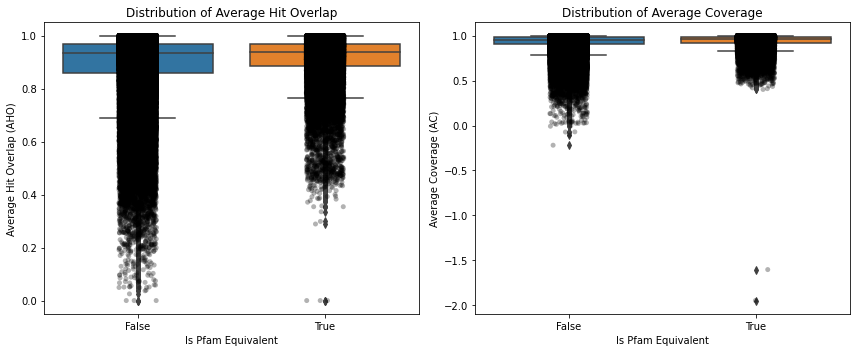

In [18]:
# 4. Visualization
plt.figure(figsize=(12, 5))

# Boxplot for Average Hit Overlap
plt.subplot(1, 2, 1)
sns.boxplot(x='is.pfam.equiv', y='avg_hits_overlap', data=clustering_stats)
sns.stripplot(x='is.pfam.equiv', y='avg_hits_overlap', data=clustering_stats,
              color='black', alpha=0.3, jitter=True)
plt.title("Distribution of Average Hit Overlap")
plt.xlabel("Is Pfam Equivalent")
plt.ylabel("Average Hit Overlap (AHO)")

# Boxplot for Average Coverage
plt.subplot(1, 2, 2)
sns.boxplot(x='is.pfam.equiv', y='avg_hit_coverage', data=clustering_stats)
sns.stripplot(x='is.pfam.equiv', y='avg_hit_coverage', data=clustering_stats,
              color='black', alpha=0.3, jitter=True)
plt.title("Distribution of Average Coverage")
plt.xlabel("Is Pfam Equivalent")
plt.ylabel("Average Coverage (AC)")

plt.tight_layout()
plt.show()
# plt.savefig("combined_plots.png")
plt.close()

In [19]:
# 5. Calculate cut-offs

equiv_stats = clustering_stats[clustering_stats['is.pfam.equiv']]
lowerbound_ac = equiv_stats['avg_hit_coverage'].quantile([0.05, 0.1, 0.2, 0.25])
lowerbound_aho = equiv_stats['avg_hits_overlap'].quantile([0.05, 0.1, 0.2, 0.25])

cutoff_ac = round(lowerbound_ac.loc[0.10], 2)
cutoff_aho = round(lowerbound_aho.loc[0.10], 2)

stats_qcfs = clustering_stats[
    (clustering_stats['avg_hits_overlap'] >= cutoff_aho) &
    (clustering_stats['avg_hit_coverage'] >= cutoff_ac)
]
print(f"Number of qualified entries: {len(stats_qcfs)}")

Number of qualified entries: 145143


In [20]:
print('AC:', cutoff_ac, ' AHO:', cutoff_aho)

AC: 0.87  AHO: 0.81


In [21]:
# filter clusters
clustering_stats = clustering_stats[clustering_stats['avg_hits_overlap'] >= 0.81]
clustering_stats = clustering_stats[clustering_stats['avg_hit_coverage'] >= 0.87]
clustering_stats = clustering_stats[clustering_stats['qecf_span'] >= 20]
clustering_stats

,Unnamed: 0,qname,cluster,nb_hits,avg_hits_overlap,qecf_raw_span,avg_hit_len_to_qecf_raw_span,raw_span_to_qlength,qecf_raw_start,qecf_raw_stop,qecf_start,qecf_end,qecf_span,avg_hit_coverage,span_to_qlength,qecf.name,max.pfam.overlap,is.pfam.equiv
0,0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280,171,280,110,0.942424,0.317003,reprseq032026_0,NaN,False
2,2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212,2,212,211,0.886030,0.271208,reprseq006261_1,0.971564,True
3,3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78,11,78,68,0.964100,0.871795,reprseq072278_0,NaN,False
4,4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851,4,851,848,0.984670,0.996475,reprseq079822_0,0.163915,False
5,5,reprseq079822,1,124,0.925391,542,0.651485,0.636898,1,542,3,366,364,0.958104,0.427732,reprseq079822_1,0.381868,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176116,176116,reprseq053363,0,35,0.954620,383,0.960612,1.000000,1,383,3,383,381,0.967529,0.994778,reprseq053363_0,0.934383,True
176118,176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110,2,110,109,0.964641,0.990909,reprseq067124_0,0.862385,True
176119,176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99,1,99,99,0.993266,0.900000,reprseq067124_1,0.949495,True
176120,176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103,10,102,93,0.962366,0.845455,reprseq067124_2,0.946237,True


### Build MSA

In [22]:
# divide clustering stats table into sub-tables
n_cores = 48

chunk_size = int(len(clustering_stats) / n_cores)
clustering_stats_parts = []
for i in range(n_cores-1):
    clustering_stats_parts.append(clustering_stats[i*chunk_size:(i+1)*chunk_size])
clustering_stats_parts.append(clustering_stats[(n_cores-1)*chunk_size:])

parts_dir = workdir_path + '/ecf-explorer/intermediate/qecf_dfs/'
for i, clustering_stats_part in enumerate(clustering_stats_parts):
    clustering_stats_part.to_csv(parts_dir + 'clustering_stats-' + str(i) + '.csv', index=False)

In [23]:
# run in parallel python script to process sub-table
# store repr-seqs.fa file in /input direcotry before running the job
# store the results of all-vs-all/ reprseq in input/ directory before running the job
# make sure filenames in all-vs-all are in the pattern excluding "-hhfilter"

msa_params = {'ident_cut':0.1, 
              'qcov_cut':0.0, 
              'eval_cut':1e-2}

script_filepath =  workdir_path + '/ecf-explorer/scripts/run-generate-qecf-msa.sh'

cmd = '#!/bin/bash\n\n'
cmd += 'FILE=$(basename "${1}")\n'
cmd += 'FILE=${FILE%.*}\n'
cmd += 'source ' + ecf_env_path + '/bin/activate\n'
cmd += 'python3 {}/ecfs/run_generate_msa_single_table.py {} {} {} {} {} {}\n'.format(
lib_ecf_path, workdir_path, '${1}', msa_params['ident_cut'], msa_params['qcov_cut'], 
msa_params['eval_cut'], lib_ecf_path)

with open(script_filepath, 'w') as file_sh:
    file_sh.write(cmd)
    
# set execute mode
call('chmod a+x ' + script_filepath, shell=True)

0

### Reformat FASTA - > A3M step

In [4]:
# run hhsuite script with reformat (slurm)
# perl reformat.pl fas a3m '~/ecf-explorer/intermediate/qecf_msa/*.fasta' .a3m

In [ ]:
# move fasta files from qecf_msa so there are only a3m files left - hhsuite builds upon all seq files in the dir

### Create qECFs hhsuite database and run all-vs-all qECF scan

In [31]:
# functions - those are the same as in protein modularity code but adjusted to ECF workdir structure

def build_hh_db_qecf(work_dir, hhsuite_bins, hhsuite_scripts, ind_profile_dir, db_dirpath, script_filepath, db_name):

    """Build HH-suite database from profiles of representative sequences."""

    # if db exists: ask to overwrite
    db_status = len(glob.glob(db_dirpath + '/*'))
    if db_status > 0:
        confirm = input('Database already exists. Overwrite? [y/n]')
        if confirm == 'y':
            cmd_clean_db = 'rm {}/*'.format(db_dirpath)
            call(cmd_clean_db, shell=True)
            print('Database cleaned.')

    db_status = len(glob.glob(db_dirpath + '/*'))
    if db_status == 0:
        cmd_bash     = '#!/bin/bash\n'
        cmd0         = 'export PATH="{}:{}:$PATH"'.format(hhsuite_bins, hhsuite_scripts)
        cmd_make_a3m = 'ffindex_build -s {0}/{1}_a3m.ff{{data,index}} {2}'.format(db_dirpath, db_name, ind_profile_dir)
        cmd_make_hmm = 'ffindex_apply {0}/{1}_a3m.ff{{data,index}} -i {0}/{1}_hmm.ffindex -d {0}/{1}_hmm.ffdata -- hhmake -i stdin -o stdout -v 0'.format(db_dirpath, db_name)
        cmd_log1     = 'echo "Created HMM profiles."'
        cmd_make_cs  = 'cstranslate -x 0.3 -c 4 -i {0}/{1}_a3m -o {0}/{1}_cs219 -I a3m -b -f'.format(db_dirpath, db_name)
        cmd_log2     = 'echo "Created column state (CS) sequence database."'

        cmd_sort1    = 'sort -k3 -n {0}/{1}_cs219.ffindex | cut -f1 > {0}/sorting.dat'.format(db_dirpath, db_name)   
        cmd_sort2    = 'ffindex_order {0}/sorting.dat {0}/{1}_hmm.ff{{data,index}} {0}/{1}_hmm_ordered.ff{{data,index}}'.format(db_dirpath, db_name)
        cmd_sort3    = 'mv {0}/{1}_hmm_ordered.ffindex {0}/{1}_hmm.ffindex'.format(db_dirpath, db_name)
        cmd_sort4    = 'mv {0}/{1}_hmm_ordered.ffdata {0}/{1}_hmm.ffdata'.format(db_dirpath, db_name)
        cmd_sort5    = 'ffindex_order {0}/sorting.dat {0}/{1}_a3m.ff{{data,index}} {0}/{1}_a3m_ordered.ff{{data,index}}'.format(db_dirpath, db_name)
        cmd_sort6    = 'mv {0}/{1}_a3m_ordered.ffindex {0}/{1}_a3m.ffindex'.format(db_dirpath, db_name)
        cmd_sort7    = 'mv {0}/{1}_a3m_ordered.ffdata {0}/{1}_a3m.ffdata'.format(db_dirpath, db_name)
        cmd_sort8    = 'rm {0}/sorting.dat'.format(db_dirpath)
        cmd_log3     = 'echo "DB sorted."'

        with open(script_filepath, 'w') as file_sh:
            for cmd in [cmd_bash, cmd0, cmd_make_a3m, cmd_make_hmm, cmd_log1,
                        cmd_make_cs, cmd_log2,
                        cmd_sort1, cmd_sort2, cmd_sort3, cmd_sort4, cmd_sort5,
                        cmd_sort6, cmd_sort7, cmd_sort8, cmd_log3]:
                file_sh.write(cmd + '\n\n')
    
    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)

    
def run_all_vs_all_qecf(hhsuite_bins, hhsuite_scripts, n, p, 
                   db_dirpath, script_filepath, db_name, output_dir):

    """Run HMM comparison of all representative proteins agains each other."""

    out_hhr = output_dir + '/${FILE}.hhr'
    output  = output_dir + '/${FILE}.o'

    cmd0 = '#!/bin/bash\n\n'
    cmd0 = cmd0 + 'export PATH="{}:{}:$PATH"\n\n'.format(hhsuite_bins, hhsuite_scripts)
    cmd1 = 'FILE=$(basename "${1}")\nFILE=${FILE%.*}\n'
   
    cmd2 = '{}/hhsearch -cpu 2 -i $1 -d ${{MEMFS}}/{}/{} -o {} -n {} -p {} -z 1 -Z 32000 -loc -v 0 -b 1 -B 32000 -ssm 2 -sc 1 -seq 1 -dbstrlen 10000 -norealign -maxres 32000 &> {}'.format(
    hhsuite_bins, db_dirpath, db_name, out_hhr, n, p, output)

    with open(script_filepath, 'w') as fb:
        for cmd in [cmd0, cmd1, cmd2]:
            fb.write(cmd)

    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)    

def build_hhr_table_qecf(work_dir, output_hhblits_dirpath, hhr_table_filpath):

    """Build a table of results from hhr files."""

    with open(hhr_table_filpath, 'w') as ftable:
        ftable.write('qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval\n') # write header

        for fhhr in sorted(glob.glob(output_hhblits_dirpath + '/*.hhr')):
            qname    = fhhr.split('/')[-1].split('.')[0]
            parser   = HHOutputParser(alignments=True)
            try:
                hit_list = parser.parse_file(fhhr)
                for hit in hit_list:
                    record = ','.join([ str(i) for i in [qname, hit.qstart, hit.qend,
                                        hit.qlength, 'ecf_' + hit.id, hit.start, hit.end, hit.slength,
                                        int(hit.identity), hit.score, hit.evalue, (hit.probability * 100),
                                        hit.pvalue]])

                    ftable.write(record + '\n')
            except:
                print('Alignment error in', fhhr)
                
def read_hhr(filename, add_full_names_when_possible=True, add_pident_when_possible=False):
    """Rafal's script translted from R by Perplexity."""
    
    hhr_table = pd.DataFrame(columns=["subject.name", "hit.probability", "e.value", "p.value", "bit.score", 
                                      "secondary.structure", "no.matches", "query.start", "query.end", "query.match.cols", 
                                      "subject.start", "subject.end", "subject.match.cols"])
    this_file_is_hhsearch = False
    
    def get_identity(hhr_alignment_detail_string):
        # Extract the identity percentage from alignment detail string
        match = re.search(r"Identities=(\d+(?:\.\d+)?)%", hhr_alignment_detail_string)
        if match:
            return float(match.group(1))
        return None

    try:
        with open(filename, "r") as file:
            this_hhsearch_output = file.readlines()
    except Exception as e:
        print(f"Error reading file '{filename}': {e}")
        return hhr_table

    file_nonempty = len(this_hhsearch_output) > 0
    test_string = " No Hit"
    test_al_string = r"No 1$"

    if file_nonempty:
        this_file_is_hhsearch = any(test_string in line for line in this_hhsearch_output)
        this_file_contains_alignment_details = any(re.search(test_al_string, line) for line in this_hhsearch_output)
    else:
        print(f"The file '{filename}' is empty! Returning empty DataFrame.")
        return hhr_table

    if this_file_is_hhsearch:
        this_hhsearch_output_head = this_hhsearch_output[:8]
        no_matched_columns = int(re.sub("Match_columns ", "", this_hhsearch_output_head[1].strip()))
        this_hhsearch_output = this_hhsearch_output[8:-1]  # remove first 8 and last line
        no_rows = len(this_hhsearch_output)
        this_file_contains_hits = no_rows > 1

        if this_file_contains_hits:
            if this_file_contains_alignment_details:
                break_index = next(i for i, line in enumerate(this_hhsearch_output) if re.search(test_al_string, line))
                this_hhsearch_output_table = this_hhsearch_output[:break_index-1]
                this_hhsearch_output_alignments = this_hhsearch_output[break_index:-1]
                upgraded_subject_names = [line[1:].strip() for line in this_hhsearch_output_alignments if line.startswith(">")]
                no_rows_output_table = len(this_hhsearch_output_table)
                alignment_details = [this_hhsearch_output_alignments[i+1] for i, line in enumerate(this_hhsearch_output_alignments) if line.startswith(">")]
                this_hhsearch_pident = [get_identity(detail) for detail in alignment_details]
            else:
                this_hhsearch_output_table = this_hhsearch_output
                no_rows_output_table = no_rows

            # Extract entries from this_hhsearch_output_table
            for row_index in range(1, no_rows_output_table):  # from 2 to no_rows_output_table in R (1-based)
                this_row = this_hhsearch_output_table[row_index].replace("(", " ").replace(")", " ")
                this_row = re.split(r"\s+", this_row.strip())
                this_row = [x for x in this_row if x != ""]
                this_row = [this_row[1]] + this_row[-9:]

                query_start, query_end = map(int, this_row[7].split("-"))
                subject_start, subject_end = map(int, this_row[8].split("-"))

                row_data = {
                    "subject.name": this_row[0],
                    "hit.probability": float(this_row[1]),
                    "e.value": float(this_row[2]),
                    "p.value": float(this_row[3]),
                    "bit.score": float(this_row[4]),
                    "secondary.structure": float(this_row[5]),
                    "no.matches": int(this_row[6]),
                    "query.start": query_start,
                    "query.end": query_end,
                    "query.match.cols": no_matched_columns,
                    "subject.start": subject_start,
                    "subject.end": subject_end,
                    "subject.match.cols": int(this_row[9])
                }
                hhr_table = pd.concat([hhr_table, pd.DataFrame([row_data])], ignore_index=True)

        if add_full_names_when_possible and this_file_contains_alignment_details:
            hhr_table["full.subject.name"] = upgraded_subject_names
        if add_pident_when_possible and this_file_contains_alignment_details:
            hhr_table["pident"] = this_hhsearch_pident

    return hhr_table
                
def build_hhr_table_qecf_rs(filelist, hhr_table_filpath):

    """Build a table of results from hhr files with Rafal's parser. Used for hhrs that failed with csb parser."""

    if os.path.isfile(hhr_table_filpath):
        answer = input('Appending to the existing file, continute? [y/n]')
        if answer != 'y':
            return 0

    with open(hhr_table_filpath, 'a') as ftable:

        for fhhr in filelist:
            qname    = fhhr.split('/')[-1].split('.')[0]
            print(qname)

            hit_list = read_hhr(fhhr, add_pident_when_possible=True)
            for hid, hit in hit_list.iterrows():
                
                # identity is not retrieved by parser, set to nan to keep table format
                record = ','.join([ str(i) for i in [qname, hit['query.start'], hit['query.end'], 
                                                     hit['query.match.cols'], 'ecf_' + hit['subject.name'], 
                                                     hit['subject.start'], hit['subject.end'],
                                                     hit['subject.match.cols'], hit['pident'], hit['bit.score'],
                                                     hit['e.value'], hit['hit.probability'], hit['p.value']]])

                ftable.write(record + '\n')

In [7]:
# create db of all qECFs
ind_profile_dir = workdir_path + 'ecf-explorer/intermediate/qecf_msa'
db_dirpath      = workdir_path + 'ecf-explorer/intermediate/qecf_db'
script_filepath = workdir_path + 'ecf-explorer/scripts/run-make-qecf-db.sh'
qecf_db_name    = 'qecf_db'

build_hh_db_qecf(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, hhsuite_scripts=hhsuite_scripts, 
            ind_profile_dir=ind_profile_dir, db_dirpath=db_dirpath, 
            script_filepath=script_filepath, db_name=qecf_db_name)

In [5]:
# run search
# run all vs all search of qECFs
n    = 1
p    = 50

script_filepath = workdir_path + 'ecf-explorer/scripts/run-qecf-all-vs-all-memfs.sh'
db_dirpath      = 'qecf_db'
output_dir      = workdir_path + 'ecf-explorer/intermediate/qecf_all_by_all'
reprseq_db_name = 'qecf_db'

run_all_vs_all_qecf(hhsuite_bins, hhsuite_scripts, n, p, 
                   db_dirpath, script_filepath, reprseq_db_name, output_dir)

In [ ]:
# collect results - qecf table
output_qecf_dirpath  = workdir_path + 'ecf-explorer/intermediate/qecf_all_by_all'
qecf_hhr_table_filpath =  '{}/table-qecf-hhr.txt'.format(workdir_path + 'ecf-explorer/output')

build_hhr_table_qecf(workdir_path, output_qecf_dirpath, qecf_hhr_table_filpath)

Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/qecf_all_by_all/ecf_reprseq023628_1.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/qecf_all_by_all/ecf_reprseq023628_2.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/qecf_all_by_all/ecf_reprseq031690_1.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/qecf_all_by_all/ecf_reprseq048199_0.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/qecf_all_by_all/ecf_reprseq058266_1.hhr
Alignment error in /net/pr2/projects/plgrid/plggmgmcb/team/kszczepaniak/ecf-pp-workdir-082025/ecf-explorer/intermediate/qecf_all_by_all/ecf_reprseq061140_0.hhr
Alignment error in /net/pr2/projects/plg

In [32]:
# save error msgs from parser to file

# load the file to process with secondary parser
parser_errors_qecf_filepath = workdir_path + 'ecf-explorer/intermediate/qecf-ava-parser-error.txt'
qecf_hhr_table_filpath =  '{}/table-qecf-hhr.txt'.format(workdir_path + 'ecf-explorer/output')

with open(parser_errors_qecf_filepath, 'r') as file:
    missing_hhrs_raw = file.readlines()
    missing_hhrs = [hhr.split(' ')[-1].strip() for hhr in missing_hhrs_raw]

build_hhr_table_qecf_rs(missing_hhrs, qecf_hhr_table_filpath)

Appending to the existing file, continute? [y/n]y
ecf_reprseq023628_1
ecf_reprseq023628_2
ecf_reprseq031690_1
ecf_reprseq048199_0
ecf_reprseq058266_1
ecf_reprseq061140_0
ecf_reprseq072900_0
ecf_reprseq079138_0
ecf_reprseq085122_0
ecf_reprseq099135_0
ecf_reprseq103836_1
ecf_reprseq106594_1
ecf_reprseq107630_2
ecf_reprseq110663_1
ecf_reprseq116280_3
ecf_reprseq118260_0
ecf_reprseq120710_1
ecf_reprseq132572_2


### Create ECFs from qECFs - filter & run MCL

In [ ]:
# compare qcov/scov as in modularity project

In [4]:
### Define paths
output_dir = workdir_path + 'output/'
inter_dir = workdir_path + 'intermediate/'
parts_dir = workdir_path + 'ecf-explorer/intermediate/qcovscov/pair_table_chunks/'

In [33]:
### load and show all-vs-all qECF table
hhr_table_qecf = pd.read_csv('{}/table-qecf-hhr.txt'.format(workdir_path + 'ecf-explorer/output'), sep=',')
hhr_table_qecf

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval
0,ecf_reprseq000001_0,1,529,529,ecf_reprseq000001_0,1,529,529,100.0,1572.4,3.000000e-205,100.0,2.000000e-210
1,ecf_reprseq000001_0,2,528,529,ecf_reprseq123914_0,1,566,569,40.0,1370.6,4.000000e-177,100.0,3.000000e-182
2,ecf_reprseq000001_0,2,528,529,ecf_reprseq045752_0,1,508,510,30.0,1256.2,4.000000e-163,100.0,4.000000e-168
3,ecf_reprseq000001_0,1,529,529,ecf_reprseq082492_0,1,521,523,29.0,1247.9,2.000000e-161,100.0,1.000000e-166
4,ecf_reprseq000001_0,24,529,529,ecf_reprseq080402_0,1,493,494,28.0,1196.4,3.000000e-155,100.0,2.000000e-160
...,...,...,...,...,...,...,...,...,...,...,...,...,...
120715468,ecf_reprseq132572_2,54,85,85,ecf_reprseq116280_0,178,209,327,28.0,26.7,1.700000e+01,52.4,1.400000e-04
120715469,ecf_reprseq132572_2,7,34,85,ecf_reprseq088341_1,1000,1027,1155,46.0,30.6,1.800000e+01,51.6,1.500000e-04
120715470,ecf_reprseq132572_2,3,42,85,ecf_reprseq022741_0,650,693,1092,18.0,30.9,1.800000e+01,51.4,1.500000e-04
120715471,ecf_reprseq132572_2,21,85,85,ecf_reprseq109994_0,512,676,1050,35.0,30.5,1.900000e+01,51.1,1.500000e-04


In [34]:
# filter hits before calculating qcov/scov
hhr_table_qecf = hhr_table_qecf[hhr_table_qecf.prob >= 95.0]
hhr_table_qecf

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval
0,ecf_reprseq000001_0,1,529,529,ecf_reprseq000001_0,1,529,529,100.0,1572.4,3.000000e-205,100.0,2.000000e-210
1,ecf_reprseq000001_0,2,528,529,ecf_reprseq123914_0,1,566,569,40.0,1370.6,4.000000e-177,100.0,3.000000e-182
2,ecf_reprseq000001_0,2,528,529,ecf_reprseq045752_0,1,508,510,30.0,1256.2,4.000000e-163,100.0,4.000000e-168
3,ecf_reprseq000001_0,1,529,529,ecf_reprseq082492_0,1,521,523,29.0,1247.9,2.000000e-161,100.0,1.000000e-166
4,ecf_reprseq000001_0,24,529,529,ecf_reprseq080402_0,1,493,494,28.0,1196.4,3.000000e-155,100.0,2.000000e-160
...,...,...,...,...,...,...,...,...,...,...,...,...,...
120715140,ecf_reprseq132572_2,3,85,85,ecf_reprseq031143_0,9,102,1013,17.0,48.7,4.300000e-03,95.0,3.600000e-08
120715141,ecf_reprseq132572_2,1,81,85,ecf_reprseq044262_1,4,86,559,44.0,46.4,4.500000e-03,95.0,3.700000e-08
120715142,ecf_reprseq132572_2,8,70,85,ecf_reprseq122995_0,1,108,108,19.0,36.8,4.500000e-03,95.0,3.700000e-08
120715143,ecf_reprseq132572_2,35,85,85,ecf_reprseq007456_1,1,55,185,24.0,40.1,4.600000e-03,95.0,3.800000e-08


In [ ]:
# get unique pairs
# get from table_hhr qname-sname unique pairs of ids
# drop duplicated pairs (i.e. keep only one from A->B and B->A)

pair_table = hhr_table_qecf[['qname', 'sname']]
pair_table = pair_table[pair_table['qname'] != pair_table['sname']]
pair_table = pair_table.drop_duplicates()

pair_table['names'] = pair_table.apply(lambda row: str(sorted([row.qname, row.sname])), axis=1)
pair_table.drop_duplicates(subset=['names'], inplace=True)
pair_table.drop(columns=['names'], inplace=True)

pair_table

In [5]:
### Run comparison
# create script to run in parallel
# dataset will also be divided into smaller chunks to optimize computation
n_cores = 48
n_subsets = 20
prob_threshold = 50

In [19]:
# divide pair table into sub-tables
chunk_size = int(len(pair_table) / n_cores)
pair_table_parts = []
for i in range(n_cores-1):
    pair_table_parts.append(pair_table[i*chunk_size:(i+1)*chunk_size])
pair_table_parts.append(pair_table[(n_cores-1)*chunk_size:])

for i, pair_table_part in enumerate(pair_table_parts):
    pair_table_part.to_csv(parts_dir + 'pair-table-' + str(i) + '.csv', index=False)

In [21]:
# now divide into sub-subtables for smaller mem usage
for i in range(n_cores):
    pair_table_part = pd.read_csv(parts_dir + 'pair-table-' + str(i) + '.csv')
    pair_table_subsets = np.array_split(pair_table_part, n_subsets)

    for j, pair_sub in enumerate(pair_table_subsets):
        pair_sub.to_csv(parts_dir + 'pair-table-' + str(i) + '-' + str(j) + '.csv', index=False)
    os.remove(parts_dir + 'pair-table-' + str(i) + '.csv')

In [22]:
# create subtables of results to optimize mem usages
for i in range(n_cores):
    for j in range(n_subsets):
        pair_sub = pd.read_csv(parts_dir + 'pair-table-' + str(i) + '-' + str(j) + '.csv')
        qname_list = list(pair_sub['qname'].unique())
        sname_list = list(pair_sub['sname'].unique())
        
        df1 = hhr_table_qecf[(hhr_table_qecf['qname'].isin(qname_list)) & (hhr_table_qecf['sname'].isin(sname_list))]
        df2 = hhr_table_qecf[(hhr_table_qecf['qname'].isin(sname_list)) & (hhr_table_qecf['sname'].isin(qname_list))]
        df = pd.concat([df1, df2])
        df.drop_duplicates(inplace=True)
        
        df.to_csv(parts_dir + 'table-hhr-' + str(i) + '-' + str(j) + '.csv', index=False)

In [24]:
# parallel python script to process sub-table

script_filepath =  workdir_path + 'ecf-explorer/scripts/run-qecf-qcov-scov.sh'
ecf=False
run_mode = 'none'

cmd = '#!/bin/bash\n\n'
cmd += 'FILE=$(basename "${1}")\n'
cmd += 'FILE=${FILE%.*}\n'
cmd += 'source ' + ecf_env_path + '/bin/activate\n'

cmd += 'python3 {}/lib_phage/run_hits_pairwise_single_table_ecf.py {} {} {} {} {} {} {}\n'.format(
    lib_pp_path, 
        workdir_path, 
        run_mode, 
        '${1}', 
        prob_threshold, 
        n_subsets, 
        ecf, 
        lib_pp_path)

with open(script_filepath, 'w') as file_sh:
    file_sh.write(cmd)
    
# set execute mode
call('chmod a+x ' + script_filepath, shell=True)

0

In [6]:
# concatenate results, add header
part_results_filepath = workdir_path + '/ecf-explorer/output/qcovscov/' + 'repr-hits-pairwise-prob' + str(prob_threshold) + '-*.txt'
concat_results_filepath = workdir_path + '/ecf-explorer/output/qcovscov/concat/qecf-hits-pairwise-prob' + str(prob_threshold) + '.txt'
header_path = workdir_path + '/ecf-explorer/output/qcovscov/concat/header'

call('echo "qname,sname,prob,scov_min,scov_max,qcov_min,qcov_max,pident,max_cov,min_cov" > ' + header_path, shell=True)
call('cat ' + part_results_filepath + ' > ' + concat_results_filepath, shell=True)
call('cat ' + header_path + ' ' + concat_results_filepath + ' > ' + concat_results_filepath.replace('.txt', '.csv'),
     shell=True)

0

In [4]:
### load and show all-vs-all qECF table with calculated qcov and scov
hhr_table_qecf_qscov = pd.read_csv('{}/qecf-hits-pairwise-prob50.csv'.format(workdir_path + 'ecf-explorer/output/qcovscov/concat'), sep=',')

hhr_table_qecf_qscov['qcov'] = hhr_table_qecf_qscov[['qcov_min', 'qcov_max']].min(axis=1)
hhr_table_qecf_qscov['scov'] = hhr_table_qecf_qscov[['scov_min', 'scov_max']].min(axis=1)

# create qcov x scov metrics
hhr_table_qecf_qscov = hhr_table_qecf_qscov.assign(qcovxscov = lambda x: x.qcov * x.scov)

# names for determining annotations
hhr_table_qecf_qscov['qname_source'] = hhr_table_qecf_qscov['qname'].apply(lambda x: x.split('_')[1])
hhr_table_qecf_qscov['sname_source'] = hhr_table_qecf_qscov['sname'].apply(lambda x: x.split('_')[1])

hhr_table_qecf_qscov

,qname,sname,prob,scov_min,scov_max,qcov_min,qcov_max,pident,max_cov,min_cov,qcov,scov,qcovxscov,qname_source,sname_source
0,ecf_reprseq000001_0,ecf_reprseq123914_0,1.000,0.9947,0.9947,0.9962,0.9962,0.40,0.9962,0.9947,0.9962,0.9947,0.990920,reprseq000001,reprseq123914
1,ecf_reprseq000001_0,ecf_reprseq045752_0,1.000,0.9961,0.9980,0.9962,0.9981,0.30,0.9981,0.9961,0.9962,0.9961,0.992315,reprseq000001,reprseq045752
2,ecf_reprseq000001_0,ecf_reprseq082492_0,1.000,0.9962,0.9962,1.0000,1.0000,0.29,1.0000,0.9962,1.0000,0.9962,0.996200,reprseq000001,reprseq082492
3,ecf_reprseq000001_0,ecf_reprseq080402_0,1.000,0.9980,0.9980,0.9565,0.9565,0.28,0.9980,0.9565,0.9565,0.9980,0.954587,reprseq000001,reprseq080402
4,ecf_reprseq000001_0,ecf_reprseq091905_0,1.000,0.9982,0.9982,1.0000,1.0000,0.22,1.0000,0.9982,1.0000,0.9982,0.998200,reprseq000001,reprseq091905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31228548,ecf_reprseq016508_1,ecf_reprseq062621_1,0.967,0.1149,0.1149,0.8333,0.8333,0.25,0.8333,0.1149,0.8333,0.1149,0.095746,reprseq016508,reprseq062621
31228549,ecf_reprseq016508_1,ecf_reprseq081217_1,0.967,0.1009,0.1009,0.9167,0.9167,0.36,0.9167,0.1009,0.9167,0.1009,0.092495,reprseq016508,reprseq081217
31228550,ecf_reprseq016508_1,ecf_reprseq123275_0,0.969,0.0861,0.1053,0.7500,0.9167,0.36,0.9167,0.0861,0.7500,0.0861,0.064575,reprseq016508,reprseq123275
31228551,ecf_reprseq016508_1,ecf_reprseq126461_2,0.971,0.2212,0.2212,0.9583,0.9583,0.35,0.9583,0.2212,0.9583,0.2212,0.211976,reprseq016508,reprseq126461


In [5]:
# save all existing ecf_reprseq names - some may get lost in filtering
qset        = set(hhr_table_qecf_qscov['qname'].unique())
sset        = set(hhr_table_qecf_qscov['sname'].unique())
reprseq_all = qset.union(sset)

len(reprseq_all)

121323

In [6]:
### apply filters

hhr_table_qecf_qscov = hhr_table_qecf_qscov[hhr_table_qecf_qscov['sname'] != hhr_table_qecf_qscov['qname']]
hhr_table_qecf_qscov = hhr_table_qecf_qscov[hhr_table_qecf_qscov.qcov >= 0.9]
hhr_table_qecf_qscov = hhr_table_qecf_qscov[hhr_table_qecf_qscov.scov >= 0.9]

hhr_table_qecf_qscov

,qname,sname,prob,scov_min,scov_max,qcov_min,qcov_max,pident,max_cov,min_cov,qcov,scov,qcovxscov,qname_source,sname_source
0,ecf_reprseq000001_0,ecf_reprseq123914_0,1.000,0.9947,0.9947,0.9962,0.9962,0.40,0.9962,0.9947,0.9962,0.9947,0.990920,reprseq000001,reprseq123914
1,ecf_reprseq000001_0,ecf_reprseq045752_0,1.000,0.9961,0.9980,0.9962,0.9981,0.30,0.9981,0.9961,0.9962,0.9961,0.992315,reprseq000001,reprseq045752
2,ecf_reprseq000001_0,ecf_reprseq082492_0,1.000,0.9962,0.9962,1.0000,1.0000,0.29,1.0000,0.9962,1.0000,0.9962,0.996200,reprseq000001,reprseq082492
3,ecf_reprseq000001_0,ecf_reprseq080402_0,1.000,0.9980,0.9980,0.9565,0.9565,0.28,0.9980,0.9565,0.9565,0.9980,0.954587,reprseq000001,reprseq080402
4,ecf_reprseq000001_0,ecf_reprseq091905_0,1.000,0.9982,0.9982,1.0000,1.0000,0.22,1.0000,0.9982,1.0000,0.9982,0.998200,reprseq000001,reprseq091905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31228008,ecf_reprseq016508_1,ecf_reprseq132684_1,0.982,0.9167,0.9167,0.9167,0.9167,0.27,0.9167,0.9167,0.9167,0.9167,0.840339,reprseq016508,reprseq132684
31228018,ecf_reprseq016508_1,ecf_reprseq090026_5,0.982,0.9167,0.9167,0.9167,0.9167,0.32,0.9167,0.9167,0.9167,0.9167,0.840339,reprseq016508,reprseq090026
31228042,ecf_reprseq016508_1,ecf_reprseq026427_1,0.981,0.9583,0.9583,0.9583,0.9583,0.26,0.9583,0.9583,0.9583,0.9583,0.918339,reprseq016508,reprseq026427
31228060,ecf_reprseq016508_1,ecf_reprseq049056_1,0.981,0.9167,0.9167,0.9167,0.9167,0.32,0.9167,0.9167,0.9167,0.9167,0.840339,reprseq016508,reprseq049056


In [7]:
# create MCL input table
weight = 'qcovxscov'

pair_table_mcl = hhr_table_qecf_qscov[['qname', 'sname', weight]]
pair_table_mcl

,qname,sname,qcovxscov
0,ecf_reprseq000001_0,ecf_reprseq123914_0,0.990920
1,ecf_reprseq000001_0,ecf_reprseq045752_0,0.992315
2,ecf_reprseq000001_0,ecf_reprseq082492_0,0.996200
3,ecf_reprseq000001_0,ecf_reprseq080402_0,0.954587
4,ecf_reprseq000001_0,ecf_reprseq091905_0,0.998200
...,...,...,...
31228008,ecf_reprseq016508_1,ecf_reprseq132684_1,0.840339
31228018,ecf_reprseq016508_1,ecf_reprseq090026_5,0.840339
31228042,ecf_reprseq016508_1,ecf_reprseq026427_1,0.918339
31228060,ecf_reprseq016508_1,ecf_reprseq049056_1,0.840339


In [8]:
# add self-hits: this will include ECFs that did not have significant (qcov/scov filters) hits to other ECFs
# encode these "singletons" as: reprseq_id, reprseq_id, 1
reprseq_missing = reprseq_all

rseq_singletons = {i:[rseq_name, rseq_name, 1.0] for i, rseq_name in enumerate(list(reprseq_missing))}
rseq_singletons_table = pd.DataFrame.from_dict(rseq_singletons, orient='index', columns=['qname', 'sname', weight])
rseq_singletons_table

,qname,sname,qcovxscov
0,ecf_reprseq085062_0,ecf_reprseq085062_0,1.0
1,ecf_reprseq070870_0,ecf_reprseq070870_0,1.0
2,ecf_reprseq074879_2,ecf_reprseq074879_2,1.0
3,ecf_reprseq058038_2,ecf_reprseq058038_2,1.0
4,ecf_reprseq147008_1,ecf_reprseq147008_1,1.0
...,...,...,...
121318,ecf_reprseq062675_0,ecf_reprseq062675_0,1.0
121319,ecf_reprseq082024_1,ecf_reprseq082024_1,1.0
121320,ecf_reprseq036340_0,ecf_reprseq036340_0,1.0
121321,ecf_reprseq073148_0,ecf_reprseq073148_0,1.0


In [9]:
# concatenate filtered table with singleton table
pair_table_mcl_all = pd.concat([pair_table_mcl, rseq_singletons_table])
pair_table_mcl_all

,qname,sname,qcovxscov
0,ecf_reprseq000001_0,ecf_reprseq123914_0,0.990920
1,ecf_reprseq000001_0,ecf_reprseq045752_0,0.992315
2,ecf_reprseq000001_0,ecf_reprseq082492_0,0.996200
3,ecf_reprseq000001_0,ecf_reprseq080402_0,0.954587
4,ecf_reprseq000001_0,ecf_reprseq091905_0,0.998200
...,...,...,...
121318,ecf_reprseq062675_0,ecf_reprseq062675_0,1.000000
121319,ecf_reprseq082024_1,ecf_reprseq082024_1,1.000000
121320,ecf_reprseq036340_0,ecf_reprseq036340_0,1.000000
121321,ecf_reprseq073148_0,ecf_reprseq073148_0,1.000000


In [10]:
# save final input file for MCL
abc_filepath = '{}/table-qecf-qscov-hhr-mcl.abc'.format(workdir_path + 'ecf-explorer/output')
pair_table_mcl_all.to_csv(abc_filepath, sep=' ', index=False, header=False, float_format="%.4f")

In [11]:
# create script to run MCL
script_mcl_filepath = '{}/run-mcl.sh'.format(workdir_path + 'ecf-explorer/scripts')
inflation_param = '2.0'

cmd_bash = '#!/bin/bash\n'
cmd_load = '{}/mcxload -abc {} --stream-mirror -write-tab {} -o {}\n'.format(mcl_bins, 
                                                                             abc_filepath, 
                                                                             abc_filepath.replace('.abc', '.tab'), 
                                                                             abc_filepath.replace('.abc', '.mci'))
cmd_mcl = '{}/mcl {} -o {} -I {}\n'.format(mcl_bins,
                                           abc_filepath.replace('.abc', '.mci'),
                                           abc_filepath.replace('.abc', '.out'),
                                           inflation_param)

cmd_dump = '{}/mcxdump -icl {} -tabr {} -o {}'.format(mcl_bins, 
                                                      abc_filepath.replace('.abc', '.out'), 
                                                      abc_filepath.replace('.abc', '.tab'),
                                                      abc_filepath.replace('.abc', '.out.dump'))

with open(script_mcl_filepath, 'w') as file_sh:
    for cmd in [cmd_bash, cmd_load, cmd_mcl, cmd_dump]:
        file_sh.write(cmd + '\n')
    
# set execute mode
call('chmod a+x ' + script_mcl_filepath, shell=True)

0

### Create ECFs from qECFs - run hhalign

In [9]:
# use qECF similarity graph for cental qECF search
# functions - nx

def read_qecf_clusters(filepath):
    clusters = {}
    clusters_count = {'qecfs':[]}
    
    with open(filepath, 'r') as cf:
        for i, line in enumerate(cf):
            members = [qecf.strip() for qecf in line.split('\t')]
            random.shuffle(members)
            clusters['ecf_{:05d}'.format(i+1)] = members
            clusters_count['qecfs'].append(len(members))
        
    return clusters, clusters_count

def create_qecf_ordered_list(this_ecf, qecf_aba_filtered, ecf2qecf):
    # calculate central qecf

    # Step 3: Select an ECF of interest and identify associated QECFs
    this_ecf_qecfs_raw = ecf2qecf.loc[ecf2qecf["ECF"] == this_ecf, "QECFs"].values[0]
    this_ecf_qecfs = this_ecf_qecfs_raw.split()  # Split QECFs into a list
    
    if len(this_ecf_qecfs) == 1:
        return this_ecf_qecfs

    # Filter the pairwise alignments for connections within the selected ECF
    this_ecf_aba = qecf_aba_filtered[
        (qecf_aba_filtered["qname"].isin(this_ecf_qecfs)) &
        (qecf_aba_filtered["sname"].isin(this_ecf_qecfs))
    ]

    # Extract edges for the network
    edges = this_ecf_aba[["qname", "sname"]]

    # Step 4: Build and visualise the network
    G = nx.Graph()
    G.add_edges_from(edges.values)

    # Calculate degree centrality and find the node with the highest centrality
    degree_centrality = nx.degree_centrality(G)
    central_qecf = max(degree_centrality, key=degree_centrality.get)

    other_qecf_to_central = this_ecf_aba[
        (this_ecf_aba["qname"] == central_qecf) |
        (this_ecf_aba["sname"]== central_qecf)]

    qecf_order = [central_qecf]
    for i, qecf in other_qecf_to_central.sort_values('qcovxscov', ascending=False).iterrows():
        if qecf['qname'] == central_qecf:
            qecf_order.append(qecf['sname'])
        elif qecf['sname'] == central_qecf:
            qecf_order.append(qecf['qname'])
        else:
            print('Error: no central qecf')
    return qecf_order

def create_script_hhalign_nx(work_dir, hhsuite_bins, hhsuite_scripts, filter_max_id, filter_cov):
    script_filepath = work_dir + 'ecf-explorer/scripts/run-hhalign-qecfs-nx.sh'

    cmd0 = '#!/bin/bash\n'
    cmd0 = cmd0 + 'export PATH="{}:{}:$PATH"\n'.format(hhsuite_bins, hhsuite_scripts)
    
    cmd1 = 'ECF=$(basename "${1}")'
    
    cmd3 = "FILE1=$(sed '1!d' ${1}/${ECF}_file_list.txt)"
    cmd4 = "FILE2=$(sed '2!d' ${1}/${ECF}_file_list.txt)"
    cmd5 = "n=0\npart=0\nfsize=$(sed -n '$=' ${1}/${ECF}_file_list.txt)\n"
    cmd6 = 'if [ $fsize -eq 1 ]; then\n' + 'cp ${FILE1} ${1}/${ECF}_final.a3m'
    cmd7 = 'elif [ $fsize -eq 2 ]; then\n' + '{}/hhalign -i ${{FILE1}} -t ${{FILE2}} -o ${{1}}/${{ECF}}_final.hhr -oa3m ${{1}}/${{ECF}}_final.a3m -v 1'.format(hhsuite_bins)
    cmd8 = 'else\n{}/hhalign -i ${{FILE1}} -t ${{FILE2}} -o ${{1}}/${{ECF}}_part_0.hhr -oa3m ${{1}}/${{ECF}}_part_0.a3m -v 1\nfi'.format(hhsuite_bins)
     
    cmd_loop1 = 'while read -r line; do\n# skip first two\n' + 'echo $n $part $fsize\n' + 'if [ $n -le 1 ]; then\n((n++))\ncontinue\nfi\n'
    cmd_loop2 = '# if main\nif [ $n -lt $((fsize-1)) ]; then'
    cmd_loop3 = '{}/hhalign -i ${{1}}/${{ECF}}_part_${{part}}.a3m -t $line -o ${{1}}/${{ECF}}_part_$((part+1)).hhr -oa3m ${{1}}/${{ECF}}_part_$((part+1)).a3m -v 1'.format(hhsuite_bins)
    cmd_loop4 = '((n++))\n((part++))\ncontinue\nfi\n'
    cmd_loop5 = '# if last line\nif [ $n -eq $((fsize-1)) ]; then'
    cmd_loop6 = '{}/hhalign -i ${{1}}/${{ECF}}_part_${{part}}.a3m -t $line -o ${{1}}/${{ECF}}_final.hhr -oa3m ${{1}}/${{ECF}}_final.a3m -v 1'.format(hhsuite_bins)
    cmd_loop7 = '((n++))\nfi\ndone < ${1}/${ECF}_file_list.txt\n\n'
    
    cmd_filter = '{}/hhfilter -i ${{1}}/${{ECF}}_final.a3m -o ${{1}}/${{ECF}}_final_filter.a3m -id {} -cov {}'.format(hhsuite_bins, filter_max_id, filter_cov)

    
    with open(script_filepath, 'w') as fb:
        for cmd in [cmd0, cmd1, cmd3, cmd4, cmd5, cmd6, cmd7, cmd8,
                    cmd_loop1, cmd_loop2, cmd_loop3, cmd_loop4,
                    cmd_loop5, cmd_loop6, cmd_loop7,
                    cmd_filter]:
            fb.write(cmd + '\n')
            
    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)

def create_script_hhalign_nx_OLD(work_dir, hhsuite_bins, hhsuite_scripts, max_id, p, cov):
    script_filepath = work_dir + 'ecf-explorer/scripts/run-hhalign-qecfs-nx.sh'

    cmd0 = '#!/bin/bash\n'
    cmd0 = cmd0 + 'export PATH="{}:{}:$PATH"\n'.format(hhsuite_bins, hhsuite_scripts)
    
    cmd1 = 'ECF=$(basename "${1}")'
    
    cmd3 = "FILE1=$(sed '1!d' ${1}/${ECF}_file_list.txt)"
    cmd4 = "FILE2=$(sed '2!d' ${1}/${ECF}_file_list.txt)"
    cmd5 = "n=0\npart=0\nfsize=$(sed -n '$=' ${1}/${ECF}_file_list.txt)\n"
    cmd6 = 'if [ $fsize -eq 1 ]; then\n' + 'cp ${FILE1} ${1}/${ECF}_final.a3m'
    cmd7 = 'elif [ $fsize -eq 2 ]; then\n' + '{}/hhalign -i ${{FILE1}} -t ${{FILE2}} -o ${{1}}/${{ECF}}_final.hhr -oa3m ${{1}}/${{ECF}}_final.a3m -v 1 -id {} -p {} -cov {}'.format(hhsuite_bins, max_id, p, cov)
    cmd8 = 'else\n{}/hhalign -i ${{FILE1}} -t ${{FILE2}} -o ${{1}}/${{ECF}}_part_0.hhr -oa3m ${{1}}/${{ECF}}_part_0.a3m -v 1 -id {} -p {} -cov {}\nfi'.format(hhsuite_bins, max_id, p, cov)
     
    cmd_loop1 = 'while read -r line; do\n# skip first two\n' + 'echo $n $part $fsize\n' + 'if [ $n -le 1 ]; then\n((n++))\ncontinue\nfi\n'
    cmd_loop2 = '# if main\nif [ $n -lt $((fsize-1)) ]; then'
    cmd_loop3 = '{}/hhalign -i ${{1}}/${{ECF}}_part_${{part}}.a3m -t $line -o ${{1}}/${{ECF}}_part_$((part+1)).hhr -oa3m ${{1}}/${{ECF}}_part_$((part+1)).a3m -v 1 -id {} -p {} -cov {}'.format(hhsuite_bins, max_id, p, cov)
    cmd_loop4 = '((n++))\n((part++))\ncontinue\nfi\n'
    cmd_loop5 = '# if last line\nif [ $n -eq $((fsize-1)) ]; then'
    cmd_loop6 = '{}/hhalign -i ${{1}}/${{ECF}}_part_${{part}}.a3m -t $line -o ${{1}}/${{ECF}}_final.hhr -oa3m ${{1}}/${{ECF}}_final.a3m -v 1 -id {} -p {} -cov {}'.format(hhsuite_bins, max_id, p, cov)
    cmd_loop7 = '((n++))\nfi\ndone < ${1}/${ECF}_file_list.txt'

    
    with open(script_filepath, 'w') as fb:
        for cmd in [cmd0, cmd1, cmd3, cmd4, cmd5, cmd6, cmd7, cmd8,
                    cmd_loop1, cmd_loop2, cmd_loop3, cmd_loop4,
                    cmd_loop5, cmd_loop6, cmd_loop7]:
            fb.write(cmd + '\n')
            
    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)

<AxesSubplot:>

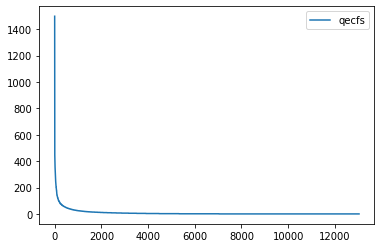

In [7]:
# read clustering results
mcl_out_filepath = '{}/table-qecf-qscov-hhr-mcl.out.dump'.format(workdir_path + 'ecf-explorer/output')
clusters, clusters_count = read_qecf_clusters(mcl_out_filepath)

cluster_count = pd.DataFrame.from_dict(clusters_count)
cluster_count.plot()

In [8]:
# create file mapping ECF names to clusters (output dir)
ecf2qecfs = pd.DataFrame.from_dict({k:' '.join(v) for k,v in clusters.items()}, orient='index', columns=['members'])
ecf2qecfs.to_csv(workdir_path + 'ecf-explorer/output/ecf2qecfs.csv', header=False)
ecf2qecfs

,members
ecf_00001,ecf_reprseq014237_0 ecf_reprseq054113_0 ecf_re...
ecf_00002,ecf_reprseq063152_0 ecf_reprseq143129_0 ecf_re...
ecf_00003,ecf_reprseq117779_2 ecf_reprseq047983_1 ecf_re...
ecf_00004,ecf_reprseq029201_1 ecf_reprseq070308_0 ecf_re...
ecf_00005,ecf_reprseq124318_0 ecf_reprseq097885_0 ecf_re...
...,...
ecf_13033,ecf_reprseq135140_1
ecf_13034,ecf_reprseq101114_3
ecf_13035,ecf_reprseq052666_2
ecf_13036,ecf_reprseq101272_0


In [9]:
# Step 1: Load the data
# Pairwise alignment results
qecf_aba = pd.read_csv('{}/qecf-hits-pairwise-prob50.csv'.format(workdir_path + 'ecf-explorer/output/qcovscov/concat'), sep=',')
display(qecf_aba)

# Mapping of ECFs to QECFs
ecf2qecf = pd.read_csv(workdir_path + 'ecf-explorer/output/ecf2qecfs.csv', header=None, names=["ECF", "QECFs"])
display(ecf2qecf)

# Additional QECF statistics
qecf_stats = pd.read_csv(workdir_path + '/ecf-explorer/output/reprseq-all-stat-coverage.txt')
display(qecf_stats)

# Optional cleanup
qecf_stats["qecf_name"] = qecf_stats.apply(lambda row : 'ecf_' + row.qname + '_' + str(row.cluster), axis=1)

# Step 2: Filter pairwise alignments for high coverage (>=90%)
qecf_aba["qcov"] = qecf_aba[["qcov_min", "qcov_max"]].min(axis=1)
qecf_aba["scov"] = qecf_aba[["scov_min", "scov_max"]].min(axis=1)
qecf_aba_filtered = qecf_aba[(qecf_aba["qcov"] >= 0.9) & (qecf_aba["scov"] >= 0.9)]
qecf_aba_filtered = qecf_aba_filtered.assign(qcovxscov = lambda x: x.qcov * x.scov)
display(qecf_aba_filtered)

,qname,sname,prob,scov_min,scov_max,qcov_min,qcov_max,pident,max_cov,min_cov
0,ecf_reprseq000001_0,ecf_reprseq123914_0,1.000,0.9947,0.9947,0.9962,0.9962,0.40,0.9962,0.9947
1,ecf_reprseq000001_0,ecf_reprseq045752_0,1.000,0.9961,0.9980,0.9962,0.9981,0.30,0.9981,0.9961
2,ecf_reprseq000001_0,ecf_reprseq082492_0,1.000,0.9962,0.9962,1.0000,1.0000,0.29,1.0000,0.9962
3,ecf_reprseq000001_0,ecf_reprseq080402_0,1.000,0.9980,0.9980,0.9565,0.9565,0.28,0.9980,0.9565
4,ecf_reprseq000001_0,ecf_reprseq091905_0,1.000,0.9982,0.9982,1.0000,1.0000,0.22,1.0000,0.9982
...,...,...,...,...,...,...,...,...,...,...
31228548,ecf_reprseq016508_1,ecf_reprseq062621_1,0.967,0.1149,0.1149,0.8333,0.8333,0.25,0.8333,0.1149
31228549,ecf_reprseq016508_1,ecf_reprseq081217_1,0.967,0.1009,0.1009,0.9167,0.9167,0.36,0.9167,0.1009
31228550,ecf_reprseq016508_1,ecf_reprseq123275_0,0.969,0.0861,0.1053,0.7500,0.9167,0.36,0.9167,0.0861
31228551,ecf_reprseq016508_1,ecf_reprseq126461_2,0.971,0.2212,0.2212,0.9583,0.9583,0.35,0.9583,0.2212


,ECF,QECFs
0,ecf_00001,ecf_reprseq014237_0 ecf_reprseq054113_0 ecf_re...
1,ecf_00002,ecf_reprseq063152_0 ecf_reprseq143129_0 ecf_re...
2,ecf_00003,ecf_reprseq117779_2 ecf_reprseq047983_1 ecf_re...
3,ecf_00004,ecf_reprseq029201_1 ecf_reprseq070308_0 ecf_re...
4,ecf_00005,ecf_reprseq124318_0 ecf_reprseq097885_0 ecf_re...
...,...,...
13032,ecf_13033,ecf_reprseq135140_1
13033,ecf_13034,ecf_reprseq101114_3
13034,ecf_13035,ecf_reprseq052666_2
13035,ecf_13036,ecf_reprseq101272_0


,Unnamed: 0,qname,cluster,nb_hits,avg_hits_overlap,qecf_raw_span,avg_hit_len_to_qecf_raw_span,raw_span_to_qlength,qecf_raw_start,qecf_raw_stop,qecf_start,qecf_end,qecf_span,avg_hit_coverage,span_to_qlength
0,0,reprseq032026,0,9,0.908336,118,0.877589,0.340058,163,280,171,280,110,0.942424,0.317003
1,1,reprseq006261,0,1377,0.644978,778,0.669754,1.000000,1,778,10,672,663,0.768557,0.852185
2,2,reprseq006261,1,21,0.855147,212,0.877583,0.272494,1,212,2,212,211,0.886030,0.271208
3,3,reprseq072278,0,34,0.956263,69,0.938193,0.884615,10,78,11,78,68,0.964100,0.871795
4,4,reprseq079822,0,26,0.973101,851,0.980475,1.000000,1,851,4,851,848,0.984670,0.996475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176117,176117,reprseq053363,1,290,0.647185,336,0.652514,0.877285,1,336,4,298,295,0.736154,0.770235
176118,176118,reprseq067124,0,144,0.955797,110,0.947790,1.000000,1,110,2,110,109,0.964641,0.990909
176119,176119,reprseq067124,1,6,0.990559,99,0.983165,0.900000,1,99,1,99,99,0.993266,0.900000
176120,176120,reprseq067124,2,8,0.953953,96,0.929688,0.872727,8,103,10,102,93,0.962366,0.845455


,qname,sname,prob,scov_min,scov_max,qcov_min,qcov_max,pident,max_cov,min_cov,qcov,scov,qcovxscov
0,ecf_reprseq000001_0,ecf_reprseq123914_0,1.000,0.9947,0.9947,0.9962,0.9962,0.40,0.9962,0.9947,0.9962,0.9947,0.990920
1,ecf_reprseq000001_0,ecf_reprseq045752_0,1.000,0.9961,0.9980,0.9962,0.9981,0.30,0.9981,0.9961,0.9962,0.9961,0.992315
2,ecf_reprseq000001_0,ecf_reprseq082492_0,1.000,0.9962,0.9962,1.0000,1.0000,0.29,1.0000,0.9962,1.0000,0.9962,0.996200
3,ecf_reprseq000001_0,ecf_reprseq080402_0,1.000,0.9980,0.9980,0.9565,0.9565,0.28,0.9980,0.9565,0.9565,0.9980,0.954587
4,ecf_reprseq000001_0,ecf_reprseq091905_0,1.000,0.9982,0.9982,1.0000,1.0000,0.22,1.0000,0.9982,1.0000,0.9982,0.998200
...,...,...,...,...,...,...,...,...,...,...,...,...,...
31228008,ecf_reprseq016508_1,ecf_reprseq132684_1,0.982,0.9167,0.9167,0.9167,0.9167,0.27,0.9167,0.9167,0.9167,0.9167,0.840339
31228018,ecf_reprseq016508_1,ecf_reprseq090026_5,0.982,0.9167,0.9167,0.9167,0.9167,0.32,0.9167,0.9167,0.9167,0.9167,0.840339
31228042,ecf_reprseq016508_1,ecf_reprseq026427_1,0.981,0.9583,0.9583,0.9583,0.9583,0.26,0.9583,0.9583,0.9583,0.9583,0.918339
31228060,ecf_reprseq016508_1,ecf_reprseq049056_1,0.981,0.9167,0.9167,0.9167,0.9167,0.32,0.9167,0.9167,0.9167,0.9167,0.840339


In [10]:
# map msa files location basing on the batch when they were processed
qecf_msa_dirpath = workdir_path + 'ecf-explorer/intermediate/qecf_msa/'
batches = [i for i in range(1,5)]
qecf2batch = {}
for batch in batches:
    for qecf in glob.glob(qecf_msa_dirpath + 'batch_' + str(batch) + '/*.a3m'):
        qecf2batch[qecf.split('/')[-1].replace('.a3m', '')] = 'batch_' + str(batch)

In [ ]:
# create directory for each ECF, copy its files to it (a3m)
ecfs_dirpath     = workdir_path + 'ecf-explorer/intermediate/ecfs/'
qecf_msa_dirpath = workdir_path + 'ecf-explorer/intermediate/qecf_msa/'

for i, ecf in ecf2qecf.iterrows():
    ordered_qecf_list = create_qecf_ordered_list(ecf[0], qecf_aba_filtered, ecf2qecf)
    
    files_to_copy = ','.join([qecf2batch[f] + '/' + f + '.a3m' for f in ordered_qecf_list])
    
    call('mkdir {}{}'.format(ecfs_dirpath, ecf[0]), shell=True)
    
    # create qecf filelist & copy only files from here
    with open(ecfs_dirpath + ecf[0] + '/' + ecf[0] + '_file_list.txt', 'w') as flf:
        for qecf in ordered_qecf_list:
            flf.write(ecfs_dirpath + ecf[0] + '/' + qecf + '.a3m\n')
    
    if len(ordered_qecf_list) == 1:
        call('cp {0}{1} {2}{3}/'.format(qecf_msa_dirpath, files_to_copy, ecfs_dirpath, ecf[0]), shell=True)
    else:
        call('cp {0}{{{1}}} {2}{3}/'.format(qecf_msa_dirpath, files_to_copy, ecfs_dirpath, ecf[0]), shell=True)

In [20]:
# DEPRECATED
# create script & run incremental a3m build with hhalign
# create_script_hhalign_nx_OLD(workdir_path, hhsuite_bins, hhsuite_scripts, max_id=95, p=95, cov=80)

In [10]:
# create script & run incremental a3m build with hhalign
create_script_hhalign_nx(workdir_path, hhsuite_bins, hhsuite_scripts, filter_max_id=95, filter_cov=50)

In [11]:
# copy final a3m to output directory so it can be used to make hhsuite db of ECFs
ecfs_dirpath       = workdir_path + 'ecf-explorer/intermediate/ecfs/'
ecfs_final_dirpath = workdir_path + 'ecf-explorer/output/ecfs/'

for ecf in glob.glob(ecfs_dirpath + '*'):
    ecf_id = ecf.split('/')[-1]
    # copy file BEFORE filtering (for debug purpose, do NOT copy for production)
    source_path = '{}/{}_final.a3m'.format(ecf, ecf_id)
    call('cp {} {}'.format(source_path, ecfs_final_dirpath), shell=True)
    
    # copy files AFTER filtering (final result for ECF db build)
    source_path_final = '{}/{}_final_filter.a3m'.format(ecf, ecf_id)
    call('cp {} {}'.format(source_path_final, ecfs_final_dirpath), shell=True)

In [ ]:
### FILTERING EFFECT ANALYSIS: BEGIN

In [31]:
# check how many sequences before and after filtering
ecfs_dirpath       = workdir_path + 'ecf-explorer/intermediate/ecfs/'
ecfs_final_dirpath = workdir_path + 'ecf-explorer/output/ecfs/'
seq_count_filepath = workdir_path + 'ecf-explorer/output/ecf_seqcount.csv'

# delete file before re-running
# call('touch {}'.format(seq_count_filepath), shell=True)

for ecf in glob.glob(ecfs_dirpath + '*'):
    ecf_id = ecf.split('/')[-1]
    
    call('echo {} | tr "\n" " " >> {}'.format(ecf_id, seq_count_filepath), shell=True)
    call('grep ">" {}/{}_final.a3m | wc -l | tr "\n" " " >> {}'.format(ecfs_final_dirpath, ecf_id, seq_count_filepath), 
         shell =True)
    call('grep ">" {}/{}_final_filter.a3m | wc -l >> {}'.format(ecfs_final_dirpath, ecf_id, seq_count_filepath), 
         shell =True)

In [5]:
seq_count_filepath = workdir_path + 'ecf-explorer/output/ecf_seqcount.csv'

ecf_seq_counts = pd.read_csv(seq_count_filepath, header=None, sep =' ')
ecf_seq_counts = ecf_seq_counts.rename(columns={0: 'ECF', 1:'before_filter', 2:'after_filter'})
ecf_seq_counts['filter_difference'] = ecf_seq_counts.before_filter - ecf_seq_counts.after_filter
ecf_seq_counts = ecf_seq_counts[ecf_seq_counts['before_filter'] <= 200]
ecf_seq_counts

,ECF,before_filter,after_filter,filter_difference
0,ecf_02747,20,20,0
1,ecf_00073,112,96,16
2,ecf_10941,5,5,0
3,ecf_08460,8,8,0
4,ecf_06575,16,16,0
...,...,...,...,...
13032,ecf_03552,30,30,0
13033,ecf_05054,8,8,0
13034,ecf_07760,6,6,0
13035,ecf_09675,11,10,1


<AxesSubplot:title={'center':'Number of sequences in ECF'}, ylabel='Frequency'>

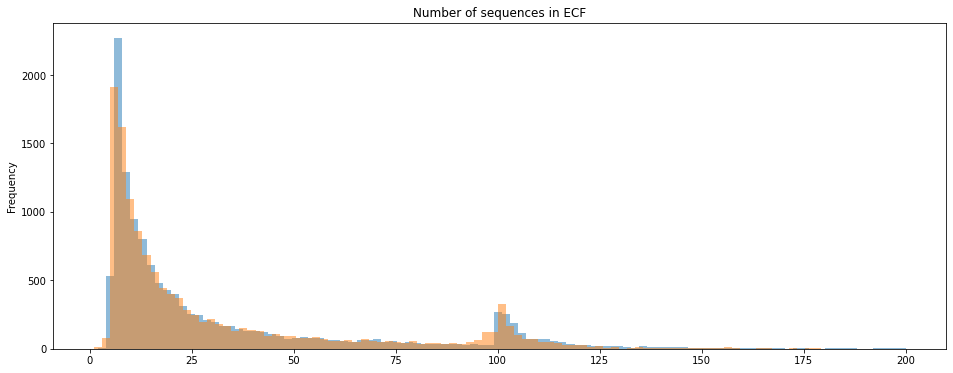

In [87]:
ecf_seq_counts['before_filter'].plot(kind='hist', bins=100, figsize=(16, 6), 
                                     title='Number of sequences in ECF', alpha=0.5)
ecf_seq_counts['after_filter'].plot(kind='hist', bins=100, figsize=(16, 6), alpha=0.5)

In [6]:
ecf_seq_counts = pd.read_csv(seq_count_filepath, header=None, sep =' ')
ecf_seq_counts = ecf_seq_counts.rename(columns={0: 'ECF', 1:'before_filter', 2:'after_filter'})
ecf_seq_counts['filter_difference'] = ecf_seq_counts.before_filter - ecf_seq_counts.after_filter

# how many with just one seq before/after filter
print('>>just one<<')
print('before', len(ecf_seq_counts[ecf_seq_counts['before_filter'] < 2]))
print('after', len(ecf_seq_counts[ecf_seq_counts['after_filter'] < 2]))
display(ecf_seq_counts[ecf_seq_counts['after_filter'] < 2])
print()

# how many with less than 3 seq before/after filter
print('>>less than three<<')
print('before', len(ecf_seq_counts[ecf_seq_counts['before_filter'] < 3]))
print('after', len(ecf_seq_counts[ecf_seq_counts['after_filter'] < 3]))
print()

# how many with less than 5 seq before/after filter
print('>>less than five<<')
print('before', len(ecf_seq_counts[ecf_seq_counts['before_filter'] < 5]))
print('after', len(ecf_seq_counts[ecf_seq_counts['after_filter'] < 5]))
print()

# how many filtered anything
print('filtered antything')
print(len(ecf_seq_counts[ecf_seq_counts['filter_difference'] != 0]))

>>just one<<
before 0
after 2


,ECF,before_filter,after_filter,filter_difference
593,ecf_12650,6,1,5
12375,ecf_04507,135,1,134



>>less than three<<
before 1
after 11

>>less than five<<
before 13
after 92

filtered antything
3202


In [6]:
# check how many seq per ECF was in previous version (restrictive hhalign params)
# check how many sequences before and after filtering
ecfs_dirpath       = workdir_path + 'ecf-explorer/intermediate/ecfs/'
ecfs_final_dirpath = workdir_path + 'ecf-explorer/output/ecfs_OLD/'
seq_count_filepath = workdir_path + 'ecf-explorer/output/ecf_OLD_seqcount.csv'

# delete file before re-running
call('touch {}'.format(seq_count_filepath), shell=True)

for ecf in glob.glob(ecfs_dirpath + '*'):
    ecf_id = ecf.split('/')[-1]
    
    call('echo {} | tr "\n" " " >> {}'.format(ecf_id, seq_count_filepath), shell=True)
    call('grep ">" {}/{}_final.a3m | wc -l >> {}'.format(ecfs_final_dirpath, ecf_id, seq_count_filepath), 
         shell =True)

In [16]:
seq_count_filepath = workdir_path + 'ecf-explorer/output/ecf_OLD_seqcount.csv'

ecf_seq_counts_OLD = pd.read_csv(seq_count_filepath, header=None, sep =' ')
ecf_seq_counts_OLD = ecf_seq_counts_OLD.rename(columns={0: 'ECF', 1:'seq_count'})
ecf_seq_counts_OLD = ecf_seq_counts_OLD[ecf_seq_counts_OLD['seq_count'] <= 200]
ecf_seq_counts_OLD

,ECF,seq_count
0,ecf_02747,20
1,ecf_00073,73
2,ecf_10941,5
3,ecf_08460,8
4,ecf_06575,3
...,...,...
13032,ecf_03552,11
13033,ecf_05054,8
13034,ecf_07760,6
13035,ecf_09675,11


<AxesSubplot:ylabel='Frequency'>

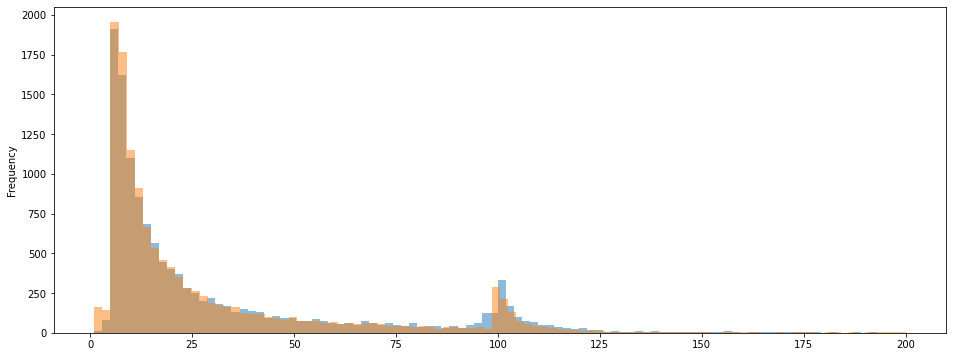

In [19]:
ecf_seq_counts['after_filter'].plot(kind='hist', bins=100, figsize=(16, 6), alpha=0.5)
ecf_seq_counts_OLD['seq_count'].plot(kind='hist', bins=100, figsize=(16, 6), alpha=0.5)

In [12]:
print('just one seq:', len(ecf_seq_counts[ecf_seq_counts['seq_count'] < 2]))

just one seq: 93


In [ ]:
### FILTERING EFFECT ANALYSIS: END

In [7]:
# move pre-filter ECFs from db creation dir
ecf_profile_dir   = workdir_path + 'ecf-explorer/output/ecfs'
ecf_prefilter_dir = workdir_path + 'ecf-explorer/output/ecfs_prefilter'

call('mv {}/*final.a3m {}'.format(ecf_profile_dir, ecf_prefilter_dir), shell=True)

0

In [14]:
# exclude ECFs that did not pass the min # seq after filtering treshold
seq_count_filepath = workdir_path + 'ecf-explorer/output/ecf_seqcount.csv'
ecf_profile_dir    = workdir_path + 'ecf-explorer/output/ecfs'
ecf_discard_dir    = workdir_path + 'ecf-explorer/output/ecfs_discard'

ecf_seq_counts = pd.read_csv(seq_count_filepath, header=None, sep =' ')
ecf_seq_counts = ecf_seq_counts.rename(columns={0: 'ECF', 1:'before_filter', 2:'after_filter'})
ecf_seq_counts['filter_difference'] = ecf_seq_counts.before_filter - ecf_seq_counts.after_filter

ecf_to_discard = ecf_seq_counts[ecf_seq_counts['after_filter'] < 2]['ECF'].to_list()
print(ecf_to_discard)

for ecf_id in ecf_to_discard:
    call('mv {}/{}_final_filter.a3m {}'.format(ecf_profile_dir, ecf_id, ecf_discard_dir), shell=True)

['ecf_12650', 'ecf_04507']


In [16]:
def build_hh_db_ecf(work_dir, hhsuite_bins, hhsuite_scripts, ind_profile_dir, db_dirpath, script_filepath, db_name):

    """Build HH-suite database from profiles of representative sequences."""

    # if db exists: ask to overwrite
    db_status = len(glob.glob(db_dirpath + '/*'))
    if db_status > 0:
        confirm = input('Database already exists. Overwrite? [y/n]')
        if confirm == 'y':
            cmd_clean_db = 'rm {}/*'.format(db_dirpath)
            call(cmd_clean_db, shell=True)
            print('Database cleaned.')

    db_status = len(glob.glob(db_dirpath + '/*'))
    if db_status == 0:
        cmd_bash     = '#!/bin/bash\n'
        cmd0         = 'export PATH="{}:{}:$PATH"'.format(hhsuite_bins, hhsuite_scripts)
        cmd_make_a3m = 'ffindex_build -s {0}/{1}_a3m.ff{{data,index}} {2}'.format(db_dirpath, db_name, ind_profile_dir)
        cmd_make_hmm = 'ffindex_apply {0}/{1}_a3m.ff{{data,index}} -i {0}/{1}_hmm.ffindex -d {0}/{1}_hmm.ffdata -- hhmake -i stdin -o stdout -v 0'.format(db_dirpath, db_name)
        cmd_log1     = 'echo "Created HMM profiles."'
        cmd_make_cs  = 'cstranslate -x 0.3 -c 4 -i {0}/{1}_a3m -o {0}/{1}_cs219 -I a3m -b -f'.format(db_dirpath, db_name)
        cmd_log2     = 'echo "Created column state (CS) sequence database."'

        cmd_sort1    = 'sort -k3 -n {0}/{1}_cs219.ffindex | cut -f1 > {0}/sorting.dat'.format(db_dirpath, db_name)   
        cmd_sort2    = 'ffindex_order {0}/sorting.dat {0}/{1}_hmm.ff{{data,index}} {0}/{1}_hmm_ordered.ff{{data,index}}'.format(db_dirpath, db_name)
        cmd_sort3    = 'mv {0}/{1}_hmm_ordered.ffindex {0}/{1}_hmm.ffindex'.format(db_dirpath, db_name)
        cmd_sort4    = 'mv {0}/{1}_hmm_ordered.ffdata {0}/{1}_hmm.ffdata'.format(db_dirpath, db_name)
        cmd_sort5    = 'ffindex_order {0}/sorting.dat {0}/{1}_a3m.ff{{data,index}} {0}/{1}_a3m_ordered.ff{{data,index}}'.format(db_dirpath, db_name)
        cmd_sort6    = 'mv {0}/{1}_a3m_ordered.ffindex {0}/{1}_a3m.ffindex'.format(db_dirpath, db_name)
        cmd_sort7    = 'mv {0}/{1}_a3m_ordered.ffdata {0}/{1}_a3m.ffdata'.format(db_dirpath, db_name)
        cmd_sort8    = 'rm {0}/sorting.dat'.format(db_dirpath)
        cmd_log3     = 'echo "DB sorted."'

        with open(script_filepath, 'w') as file_sh:
            for cmd in [cmd_bash, cmd0, cmd_make_a3m, cmd_make_hmm, cmd_log1,
                        cmd_make_cs, cmd_log2,
                        cmd_sort1, cmd_sort2, cmd_sort3, cmd_sort4, cmd_sort5,
                        cmd_sort6, cmd_sort7, cmd_sort8, cmd_log3]:
                file_sh.write(cmd + '\n\n')
    
    # set execute mode
    call('chmod a+x ' + script_filepath, shell=True)

In [17]:
# create hhsuite db of ECFs
ecf_profile_dir        = workdir_path + 'ecf-explorer/output/ecfs'
ecf_db_dirpath         = workdir_path + 'ecf-explorer/output/ecfs_db'
ecf_db_script_filepath = workdir_path + 'ecf-explorer/scripts/run-make-ecf-db.sh'
ecf_db_name            = 'ecf_db'

build_hh_db_ecf(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, hhsuite_scripts=hhsuite_scripts, 
            ind_profile_dir=ecf_profile_dir, db_dirpath=ecf_db_dirpath, 
            script_filepath=ecf_db_script_filepath, db_name=ecf_db_name)

### Scan DBs & reprseq

In [4]:
def create_script_hhsearch_dbs(work_dir, hhsuite_bins, hhsuite_scripts, 
                               db_path, db_name, script_dirpath, db_outname):

    """Run hhblits in order to search databases with profiles constructed."""

    # write bash runfile
    bash_script_filepath   = script_dirpath + 'run-search-{}.sh'.format(db_outname)
    output_hhblits_dirpath = work_dir + 'ecf-explorer/intermediate/scans/{}'.format(db_outname)
    try:
        os.mkdir(output_hhblits_dirpath) # create db dir
    except FileExistsError:
        print('output directory already set up')

    out_hhr          = output_hhblits_dirpath + '/${FILE}.hhr'
    output           = output_hhblits_dirpath + '/${FILE}.o'

    cmd0 = '#!/bin/bash\n\n'
    cmd0 = cmd0 + 'export PATH="{}:{}:$PATH"\n\n'.format(hhsuite_bins, hhsuite_scripts)
    cmd1 = 'FILE=$(basename "${1}")\nFILE=${FILE%.*}\n'    
    cmd2 = '{}/hhsearch -cpu 2 -i $1 -d ${{MEMFS}}/{}/{} -o {} -p 50 -z 1 -Z 1000 -loc -v 0 -b 1 -B 1000 -ssm 2 -sc 1 -seq 1 -dbstrlen 10000 -norealign -maxres 32000 &> {}'.format(
    hhsuite_bins, db_path, db_name, out_hhr, output)
    
    fb = open(bash_script_filepath, 'w')
    for cmd in [cmd0, cmd1, cmd2]:
        fb.write(cmd)
    fb.close()
    # set execute mode
    call('chmod a+x ' + bash_script_filepath, shell=True)
    
def build_hhr_table_dbs(work_dir, db_outname):

    """Build a table of results from hhr files."""

    output_hhblits_dirpath = work_dir + 'ecf-explorer/intermediate/scans/{}'.format(db_outname)
    hhr_table_filpath      = work_dir + 'ecf-explorer/output/table-scan-{}.txt'.format(db_outname)
    error_log_filepath     = work_dir + 'ecf-explorer/intermediate/scans/aln-error-log-{}.txt'.format(db_outname)
    
    with open(error_log_filepath, 'w') as err_file:
        with open(hhr_table_filpath, 'w') as ftable:
            ftable.write('qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval\n') # write header

            for fhhr in sorted(glob.glob(output_hhblits_dirpath + '/*.hhr')):
                qname    = fhhr.split('/')[-1].split('.')[0].replace('-hhfilter', '')
                parser   = HHOutputParser()
                try:
                    hit_list = parser.parse_file(fhhr)
                    for hit in hit_list:
                        record = ','.join([ str(i) for i in [qname, hit.qstart, hit.qend,
                                            hit.qlength, hit.id, hit.start, hit.end, hit.slength,
                                            int(hit.identity), hit.score, hit.evalue, (hit.probability * 100),
                                            hit.pvalue]])
                        ftable.write(record + '\n')
                except:
                    err_file.write(fhhr + '\n')
                    
    if os.stat(error_log_filepath).st_size != 0:
        with open(error_log_filepath, 'r') as err_file:
            print('Parsing complete. Found {} alignments with errors.'.format(len(err_file.readlines())))
            return True
    else:
        print('Done. Table completed without errors.')
        return False

def read_hhr(filename, add_full_names_when_possible=True, add_pident_when_possible=False):
    """Rafal's script translted from R by Perplexity."""
    
    hhr_table = pd.DataFrame(columns=["subject.name", "hit.probability", "e.value", "p.value", "bit.score", 
                                      "secondary.structure", "no.matches", "query.start", "query.end", "query.match.cols", 
                                      "subject.start", "subject.end", "subject.match.cols"])
    this_file_is_hhsearch = False
    
    def get_identity(hhr_alignment_detail_string):
        # Extract the identity percentage from alignment detail string
        match = re.search(r"Identities=(\d+(?:\.\d+)?)%", hhr_alignment_detail_string)
        if match:
            return float(match.group(1))
        return None

    try:
        with open(filename, "r") as file:
            this_hhsearch_output = file.readlines()
    except Exception as e:
        print(f"Error reading file '{filename}': {e}")
        return hhr_table

    file_nonempty = len(this_hhsearch_output) > 0
    test_string = " No Hit"
    test_al_string = r"No 1$"

    if file_nonempty:
        this_file_is_hhsearch = any(test_string in line for line in this_hhsearch_output)
        this_file_contains_alignment_details = any(re.search(test_al_string, line) for line in this_hhsearch_output)
    else:
        print(f"The file '{filename}' is empty! Returning empty DataFrame.")
        return hhr_table

    if this_file_is_hhsearch:
        this_hhsearch_output_head = this_hhsearch_output[:8]
        no_matched_columns = int(re.sub("Match_columns ", "", this_hhsearch_output_head[1].strip()))
        this_hhsearch_output = this_hhsearch_output[8:-1]  # remove first 8 and last line
        no_rows = len(this_hhsearch_output)
        this_file_contains_hits = no_rows > 1

        if this_file_contains_hits:
            if this_file_contains_alignment_details:
                break_index = next(i for i, line in enumerate(this_hhsearch_output) if re.search(test_al_string, line))
                this_hhsearch_output_table = this_hhsearch_output[:break_index-1]
                this_hhsearch_output_alignments = this_hhsearch_output[break_index:-1]
                upgraded_subject_names = [line[1:].strip() for line in this_hhsearch_output_alignments if line.startswith(">")]
                no_rows_output_table = len(this_hhsearch_output_table)
                alignment_details = [this_hhsearch_output_alignments[i+1] for i, line in enumerate(this_hhsearch_output_alignments) if line.startswith(">")]
                this_hhsearch_pident = [get_identity(detail) for detail in alignment_details]
            else:
                this_hhsearch_output_table = this_hhsearch_output
                no_rows_output_table = no_rows

            # Extract entries from this_hhsearch_output_table
            for row_index in range(1, no_rows_output_table):  # from 2 to no_rows_output_table in R (1-based)
                this_row = this_hhsearch_output_table[row_index].replace("(", " ").replace(")", " ")
                this_row = re.split(r"\s+", this_row.strip())
                this_row = [x for x in this_row if x != ""]
                this_row = [this_row[1]] + this_row[-9:]

                query_start, query_end = map(int, this_row[7].split("-"))
                subject_start, subject_end = map(int, this_row[8].split("-"))

                row_data = {
                    "subject.name": this_row[0],
                    "hit.probability": float(this_row[1]),
                    "e.value": float(this_row[2]),
                    "p.value": float(this_row[3]),
                    "bit.score": float(this_row[4]),
                    "secondary.structure": float(this_row[5]),
                    "no.matches": int(this_row[6]),
                    "query.start": query_start,
                    "query.end": query_end,
                    "query.match.cols": no_matched_columns,
                    "subject.start": subject_start,
                    "subject.end": subject_end,
                    "subject.match.cols": int(this_row[9])
                }
                hhr_table = pd.concat([hhr_table, pd.DataFrame([row_data])], ignore_index=True)

        if add_full_names_when_possible and this_file_contains_alignment_details:
            hhr_table["full.subject.name"] = upgraded_subject_names
        if add_pident_when_possible and this_file_contains_alignment_details:
            hhr_table["pident"] = this_hhsearch_pident

    return hhr_table
    
def build_hhr_table_dbs_rs(work_dir, db_outname):

    """Build a table of results from hhr files with Rafal's parser. Used for hhrs that failed with csb parser."""

    print('Fixing missing files with secondary parser...')
    hhr_table_filpath   = work_dir + 'ecf-explorer/output/table-scan-{}.txt'.format(db_outname)
    error_log_filepath  = work_dir + 'ecf-explorer/intermediate/scans/aln-error-log-{}.txt'.format(db_outname)
    failed_log_filepath = work_dir + 'ecf-explorer/intermediate/scans/aln-failed-log-{}.txt'.format(db_outname)
    count_fixes         = 0
    
    with open(failed_log_filepath, 'w') as failed_log:
        with open(hhr_table_filpath, 'a') as ftable:
            with open(error_log_filepath, 'r') as error_log:
                for fhhr in error_log.readlines():
                    qname = fhhr.split('/')[-1].split('.')[0].replace('-hhfilter', '')

                    try:
                        hit_list = read_hhr(fhhr.strip(), add_pident_when_possible=True)
                        for hid, hit in hit_list.iterrows():

                            # identity is not retrieved by parser, set to nan to keep table format
                            record = ','.join([ str(i) for i in [qname, hit['query.start'], hit['query.end'], 
                                                                 hit['query.match.cols'], hit['subject.name'], 
                                                                 hit['subject.start'], hit['subject.end'],
                                                                 hit['subject.match.cols'], hit['pident'], hit['bit.score'],
                                                                 hit['e.value'], hit['hit.probability'], hit['p.value']]])

                            ftable.write(record + '\n')
                        count_fixes += 1
                    except:
                        failed_log.write(fhhr)
                        
    if os.stat(failed_log_filepath).st_size != 0:
        with open(failed_log_filepath, 'r') as fail_file:
            print('Secondary parsing complete. Fixed {} alignments, {} still fail.'.format(count_fixes, 
                                                                                           len(fail_file.readlines())))
            return True
    else:
        print('Done. Table completed without errors.')
        return False
    
def delete_corrupted_aln(fhhr_read, fhhr_write, error_hits):
    
    with open(fhhr_write, 'w') as fixed_hhr:    
        with open(fhhr_read, 'r') as fread:
            lines = fread.readlines()
            pattern_header = r"\s*[" + "".join(str(num+1) for num in error_hits) + r"] .*\(.*\)"
            pattern_aln    = r"\s*No [" + "".join(str(num+1) for num in error_hits) + r"]$"
            for line in lines:
                if re.match(pattern_header, line.strip()):
                    pass
                elif re.match(pattern_aln, line.strip()):
                    pass
                else:
                    fixed_hhr.write(line)
                    
def build_hhr_table_dbs_del_aln(work_dir, db_outname):
    
    """Final fix: delete corrupted aln from file and attempt another parse with csb"""
    
    
    print('Fixing missing files with deleting corrupted alignments...')
    hhr_table_filpath   = work_dir + 'ecf-explorer/output/table-scan-{}.txt'.format(db_outname)
    hhr_all_dirpath     = work_dir + 'ecf-explorer/intermediate/scans/{}/'.format(db_outname)
    failed_log_filepath = work_dir + 'ecf-explorer/intermediate/scans/aln-failed-log-{}.txt'.format(db_outname)
    count_fails         = 0
    
    # delete corrupted aln and store into new file
    with open(failed_log_filepath, 'r') as failed_log:
        for fhhr in failed_log.readlines():
            # read file without alignment
            hhr_test = HHOutputParser(alignments=False).parse_file(fhhr.strip())
            # find aln with len == 1
            error_hits = [hid for hid, hit in enumerate(hhr_test) if hit.length == 1]
            # delete header and aln start from the file
            delete_corrupted_aln(fhhr.strip(), fhhr.strip().replace('.hhr', '-fixed.hhr'), error_hits)
    
    # parse new file with csb parser
    with open(hhr_table_filpath, 'a') as ftable:
        for fhhr_fixed in glob.glob(hhr_all_dirpath + '*-fixed.hhr'):
            qname    = fhhr_fixed.strip().split('/')[-1].split('.')[0].replace('-hhfilter', '').replace('-fixed', '')
            parser   = HHOutputParser()
            try:
                hit_list = parser.parse_file(fhhr_fixed.strip())
                for hit in hit_list:
                    record = ','.join([ str(i) for i in [qname, hit.qstart, hit.qend,
                                        hit.qlength, hit.id, hit.start, hit.end, hit.slength,
                                        int(hit.identity), hit.score, hit.evalue, (hit.probability * 100),
                                        hit.pvalue]])
                    ftable.write(record + '\n')
            except:
                count_fails += 1

    if count_fails != 0:
        print('Parser still fails in {} case. Those will not be included in the table.'.format(count_fails))
    else:
        print('Done. Table completed without errors.')

In [10]:
# rseq scans of DBs

In [ ]:
# run rseq on Pfam
db_path = 'Pfam37'
db_name = 'pfama'
db_outname = 'rseq_pfam'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [ ]:
# rseq on Pfam: gather results into table
db_outname = 'rseq_pfam'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

In [6]:
# run rseq on ECOD
db_path = 'ECOD_F70_20230309'
db_name = 'ECOD_F70_20230309'
db_outname = 'rseq_ecod'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [ ]:
# rseq on ECOD: gather results into table
db_outname = 'rseq_ecod'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

In [7]:
# run rseq on CATH
db_path = 'CATH_S40_V4p3'
db_name = 'CATH_S40'
db_outname = 'rseq_cath'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [ ]:
# rseq on CATH: gather results into table
db_outname = 'rseq_cath'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

In [8]:
# run rseq on phrogs
db_path = 'phrogs_hhsuite_db'
db_name = 'phrogs'
db_outname = 'rseq_phrogs'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [5]:
# rseq on phrogs: gather results into table
db_outname = 'rseq_phrogs'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 126 alignments with errors.
Fixing missing files with secondary parser...
Done. Table completed without errors.


In [5]:
# run rseq on ECFdb
db_path = 'ecfs_db'
db_name = 'ecf_db'
db_outname = 'rseq_ecf'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [5]:
# rseq on ECFdb: gather results into table
db_outname = 'rseq_ecf'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 231 alignments with errors.
Fixing missing files with secondary parser...
Secondary parsing complete. Fixed 230 alignments, 1 still fail.
Fixing missing files with deleting corrupted alignments...
Done. Table completed without errors.


In [8]:
### ECF scans of DBs

In [11]:
# run ECF on ECOD
db_path = 'ECOD_F70_20230309'
db_name = 'ECOD_F70_20230309'
db_outname = 'ecfs_ecod'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [ ]:
# ECF on ECOD: gather results into table
db_outname = 'ecfs_ecod'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

In [12]:
# run ECF on CATH
db_path = 'CATH_S40_V4p3'
db_name = 'CATH_S40'
db_outname = 'ecfs_cath'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [5]:
# ECF on CATH: gather results into table
db_outname = 'ecfs_cath'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 14 alignments with errors.
Fixing missing files with secondary parser...
Done. Table completed without errors.


In [13]:
# run ECF on Pfam
db_path = 'Pfam37'
db_name = 'pfama'
db_outname = 'ecfs_pfam'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [5]:
# ECF on Pfam: gather results into table
db_outname = 'ecfs_pfam'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 26 alignments with errors.
Fixing missing files with secondary parser...
Secondary parsing complete. Fixed 24 alignments, 2 still fail.
Fixing missing files with deleting corrupted alignments...
Done. Table completed without errors.


In [14]:
# run ECF on phrogs
db_path = 'phrogs_hhsuite_db'
db_name = 'phrogs'
db_outname = 'ecfs_phrogs'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [6]:
# ECF on phrogs: gather results into table
db_outname = 'ecfs_phrogs'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 10 alignments with errors.
Fixing missing files with secondary parser...
Done. Table completed without errors.


In [15]:
# run ECF on ECFdb
db_path = 'ecfs_db'
db_name = 'ecf_db'
db_outname = 'ecfs_ecf'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [7]:
# ECF on ECFdb: gather results into table
db_outname = 'ecfs_ecf'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 12 alignments with errors.
Fixing missing files with secondary parser...
Secondary parsing complete. Fixed 11 alignments, 1 still fail.
Fixing missing files with deleting corrupted alignments...
Done. Table completed without errors.


### Scans - antidefence

In [4]:
# Prepare anti-defence proteins for scan

# divide fasta file into single protein files
def save_individual_seqs_ad(work_dir):
    '''Save each of the renamed sequences into separate file.'''

    ad_prot_seqs_filepath_final = work_dir + 'ecf-explorer/input/8_Bruria2024_seq.fasta'
    tmp_dir                       = work_dir + 'ecf-explorer/intermediate/ad-ind-seqs/'

    fasta = SeqIO.parse(ad_prot_seqs_filepath_final, "fasta")
    for record in fasta:
        fasta_filename = record.id + '.fa'
        SeqIO.write(record, tmp_dir + fasta_filename, "fasta")

save_individual_seqs_ad(workdir_path)

In [6]:
# run antidefence on ECFdb
db_path = 'ecfs_db'
db_name = 'ecf_db'
db_outname = 'ad_ecf'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [5]:
# antidefence on ECFdb: gather results into table
db_outname = 'ad_ecf'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Done. Table completed without errors.


In [8]:
# run antidefence on reprseq
db_path = 'reprseq_ecf_db'
db_name = 'reprseq_ecf_db'
db_outname = 'ad_rseq'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [9]:
# antidefence on reprseq: gather results into table
db_outname = 'ad_rseq'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Done. Table completed without errors.


### Scans - PhageScope

In [5]:
# Prepare Phage Scope proteins for scan

# divide fasta file into single protein files
def save_individual_seqs_ps(work_dir):
    '''Save each of the renamed sequences into separate file.'''

    ad_prot_seqs_filepath_final = work_dir + 'ecf-explorer/input/PhageScope_protein_2000.fasta'
    tmp_dir                       = work_dir + 'ecf-explorer/intermediate/phage-scope-ind-seqs/'

    fasta = SeqIO.parse(ad_prot_seqs_filepath_final, "fasta")
    for record in fasta:
        fasta_filename = record.id + '.fa'
        SeqIO.write(record, tmp_dir + fasta_filename, "fasta")

save_individual_seqs_ps(workdir_path)

In [6]:
# run PhageScope on ECFdb
db_path = 'ecfs_db'
db_name = 'ecf_db'
db_outname = 'ps_ecf'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [ ]:
# PhageScope on ECFdb: gather results into table
db_outname = 'ps_ecf'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

In [7]:
# run PhageScope on Pfam
db_path = 'Pfam37'
db_name = 'pfama'
db_outname = 'ps_pfam'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [6]:
# PhageScope on Pfam: gather results into table
db_outname = 'ps_pfam'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 157 alignments with errors.
Fixing missing files with secondary parser...
Done. Table completed without errors.


In [8]:
# run PhageScope on ECOD
db_path = 'ECOD_F70_20230309'
db_name = 'ECOD_F70_20230309'
db_outname = 'ps_ecod'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [ ]:
# PhageScope on ECOD: gather results into table
db_outname = 'ps_ecod'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

In [9]:
# run PhageScope on CATH
db_path = 'CATH_S40_V4p3'
db_name = 'CATH_S40'
db_outname = 'ps_cath'
script_dirpath = workdir_path + 'ecf-explorer/scripts/'

create_script_hhsearch_dbs(work_dir=workdir_path, hhsuite_bins=hhsuite_bins, 
                          hhsuite_scripts=hhsuite_scripts, db_path=db_path, db_name=db_name, 
                          script_dirpath=script_dirpath, db_outname=db_outname)

In [5]:
# PhageScope on CATH: gather results into table
db_outname = 'ps_cath'
if build_hhr_table_dbs(workdir_path, db_outname):
    if build_hhr_table_dbs_rs(workdir_path, db_outname):
        build_hhr_table_dbs_del_aln(workdir_path, db_outname)

Parsing complete. Found 69 alignments with errors.
Fixing missing files with secondary parser...
Done. Table completed without errors.
